# Student Pass/Fail Prediction (Classification)

This notebook trains baseline classifiers on **weekly snapshot** rows from the EWS feature store.  
For each week `t`, we build **one row per (student_id, module, presentation)** using the latest record with `week <= t`, then evaluate performance with a **group-aware split by `student_id`** to reduce leakage across time for the same student.

We run multiple **feature-set experiments** (engagement-only, +demographics, +assessment, full) and compare models (LogReg, RandomForest). Outputs include:
- ROC-AUC over time
- Recall/precision for the **Fail (0)** class
- Confusion matrices at selected weeks (saved as figures + CSV)
- Top features for the best-performing run (saved as CSV + figure)

---


## 1. Setup & Imports <a id="1-setup"></a>

Import dependencies and define output directories (tables, figures, feature lists).

In [1]:
%reset -f

In [2]:
import numpy as np
import pandas as pd
import os
from pathlib import Path

import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    fbeta_score,
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# -----------------------
# Paths (repo-style)
# -----------------------
REPO_ROOT = Path.cwd()
if REPO_ROOT.name.lower() in {"notebooks", "notebook"}:
    REPO_ROOT = REPO_ROOT.parent

DEFAULT_REPORTS_ROOT = REPO_ROOT / "reports"
REPORTS_ROOT = Path(os.environ.get("EWS_REPORTS_DIR", str(DEFAULT_REPORTS_ROOT)))

# Processed data directory
PROC_DIR = REPO_ROOT / "data" / "processed"

OUT_ROOT = REPORTS_ROOT / "classification"

FIG_DIR  = OUT_ROOT / "figures"
TAB_DIR  = OUT_ROOT / "tables"
FEAT_DIR = OUT_ROOT / "features"

for d in [OUT_ROOT, FIG_DIR, TAB_DIR, FEAT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def slug(s: str) -> str:
    return (
        str(s).strip()
        .replace(" ", "_")
        .replace("|", "_")
        .replace("/", "_")
        .replace("\\", "_")
        .replace("__", "_")
    )

def savefig(name: str, dpi: int = 200):
    path = FIG_DIR / f"{slug(name)}.png"
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("Saved figure:", path)
    return path

print("Repo root:", REPO_ROOT)
print("Reports root:", REPORTS_ROOT)
print("Classification outputs:", OUT_ROOT)

Repo root: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project
Reports root: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports
Classification outputs: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification


---

## 2. Load Data <a id="2-load"></a>

Load the weekly EWS feature store.

In [3]:
df = pd.read_csv(PROC_DIR / "ews_feature_store.csv")

print("Shape:", df.shape)
print("Week range:", df["week"].min(), "->", df["week"].max())
print("Students:", f'{df["student_id"].nunique():,}')
df.head()


Shape: (579438, 99)
Week range: 0 -> 38
Students: 25,516


,student_id,code_module,code_presentation,week,cum_weekly_clicks_dataplus,cum_weekly_clicks_dualpane,cum_weekly_clicks_externalquiz,cum_weekly_clicks_folder,cum_weekly_clicks_forumng,cum_weekly_clicks_glossary,...,target_score_norm,weight_covered,weighted_score_week,weight_covered_week,cumulative_weighted_score_assess,weight_covered_assess,total_weight_assess,remaining_weight_assess,max_possible_final_score_assess,mathematically_impossible_to_pass
0,6516,AAA,2014J,0,0,0,0,0,124,0,...,63.5,100.0,0.0,0.0,0.0,0.0,200.0,200.0,200.0,0
1,6516,AAA,2014J,1,0,0,0,0,146,0,...,63.5,100.0,0.0,0.0,0.0,0.0,200.0,200.0,200.0,0
2,6516,AAA,2014J,2,0,0,0,0,158,0,...,63.5,100.0,6.0,10.0,6.0,10.0,200.0,190.0,196.0,0
3,6516,AAA,2014J,3,0,0,0,0,164,0,...,63.5,100.0,0.0,0.0,6.0,10.0,200.0,190.0,196.0,0
4,6516,AAA,2014J,4,7,0,0,0,184,0,...,63.5,100.0,0.0,0.0,6.0,10.0,200.0,190.0,196.0,0


---

## 3. Experiment Configuration <a id="3-config"></a>

Define keys, target, leakage columns, and column groups used by experiment variants.

In [4]:
# -----------------------
# Core config
# -----------------------
KEYS = ["student_id", "code_module", "code_presentation"]
TARGET_COL = "target_pass"

# identifiers you never want in X
IDENTIFIER_COLS = ["student_id", "code_module", "code_presentation", "week"]

# -----------------------
# Column groups (experiments)
# -----------------------
LEAKAGE_COLS = [
    "date_unregistration",
    "final_result",
    "target_score",
    "target_score_norm",

]

ASSESSMENT_COLS = [
    "weight_covered",
    "weight_covered_assess",
    "total_weight_assess",
    "remaining_weight_assess",
    "max_possible_final_score_assess",
    "mathematically_impossible_to_pass",
    "weighted_score_assess",
    "cumulative_weighted_score_assess"
    "weighted_score_week",
    "weight_covered_week",

]

DEMOGRAPHIC_COLS = [
    "highest_education", "num_of_prev_attempts", "studied_credits",
    "module_presentation_length", "date_registration",
]

PERSONAL_INFO_COLS = [
    "gender", "region", "imd_band", "age_band", "disability",
]


---

## 4. Preprocessing & Helpers <a id="4-preprocess"></a>

Key mechanics:
- **Weekly snapshot builder**: one row per student-module-presentation using latest week ≤ t
- **Group-aware split** by `student_id`
- **Preprocessor**: numeric (median + scale), categorical (most-frequent + one-hot)

In [5]:
def build_xy_for_week_snapshot(
    df: pd.DataFrame,
    t: int,
    *,
    drop_cols: list[str] | None = None,
    target_col: str = TARGET_COL,
):
    """One row per (student_id, module, presentation) using latest week <= t."""
    d = df[df["week"] <= t].copy()
    d = d.sort_values(KEYS + ["week"])
    d = d.groupby(KEYS, as_index=False).tail(1)

    d = d[d[target_col].notna()].copy()
    d[target_col] = d[target_col].astype(int)

    groups = d["student_id"].copy()

    drops = set(LEAKAGE_COLS) | set(IDENTIFIER_COLS)
    if drop_cols:
        drops |= set(drop_cols)

    # NEVER drop the target here
    drops.discard(target_col)

    # DROP FIRST
    d = d.drop(columns=[c for c in drops if c in d.columns], errors="ignore")

    # THEN CHECK
    still_in = sorted((set(LEAKAGE_COLS) | set(IDENTIFIER_COLS)) & set(d.columns))
    if still_in:
        raise ValueError(f"Leakage/ID columns still present after drop: {still_in}")

    y = d[target_col].copy()
    X = d.drop(columns=[target_col])

    return X, y, groups


def make_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    num_cols = X.select_dtypes(include=["int64", "int32", "float64", "float32"]).columns.tolist()
    cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

    num_pipe = Pipeline(steps=[
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])

    cat_pipe = Pipeline(steps=[
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer(
        transformers=[
            ("num", num_pipe, num_cols),
            ("cat", cat_pipe, cat_cols),
        ],
        remainder="drop",
    )


def group_train_test_split(X, y, groups, test_size=0.2, random_state=42):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    train_idx, test_idx = next(gss.split(X, y, groups=groups))
    return X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]


def fit_predict_week(df, t, model, *, drop_cols=None, test_size=0.2, random_state=42):
    X, y, groups = build_xy_for_week_snapshot(df, t, drop_cols=drop_cols)

    X_train, X_test, y_train, y_test = group_train_test_split(
        X, y, groups, test_size=test_size, random_state=random_state
    )

    pipe = Pipeline(steps=[
        ("prep", make_preprocessor(X_train)),  # fit-on-train only
        ("model", clone(model)),
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    proba = None
    if hasattr(pipe, "predict_proba"):
        proba = pipe.predict_proba(X_test)[:, 1]

    return pipe, X_test, y_test, y_pred, proba


def eval_week(df, t, model, *, drop_cols=None, test_size=0.2, random_state=42, fail_label=0):
    _, _, y_test, y_pred, proba = fit_predict_week(
        df, t, model, drop_cols=drop_cols, test_size=test_size, random_state=random_state
    )

    roc = float(roc_auc_score(y_test, proba)) if proba is not None else np.nan

    return {
        "week_t": int(t),
        "n_test": int(len(y_test)),
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "f1": float(f1_score(y_test, y_pred)),
        "fbeta2": float(fbeta_score(y_test, y_pred, beta=2)),
        "roc_auc": float(roc),
        "recall_fail": float(recall_score(y_test, y_pred, pos_label=fail_label)),
        "precision_fail": float(precision_score(y_test, y_pred, pos_label=fail_label)),
    }


---

## 5. Visualization & Export Utilities <a id="5-viz"></a>

Plot helpers save figures to `FIG_DIR`. Tables export to `TAB_DIR`.

In [6]:
def plot_roc_over_time(results_df: pd.DataFrame, *, title: str, fname: str | None = None):
    r = results_df.sort_values(["experiment", "model", "week_t"]).copy()

    plt.figure(figsize=(10, 4))
    for (exp, model), g in r.groupby(["experiment", "model"]):
        plt.plot(g["week_t"], g["roc_auc"], marker="o", label=f"{exp} | {model}")

    plt.title(title)
    plt.xlabel("Week t (snapshot ≤ t)")
    plt.ylabel("ROC-AUC")
    plt.ylim(0.0, 1.0)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()

    if fname:
        savefig(fname)

    plt.show()


def export_pivot(results_df: pd.DataFrame, value_col: str, out_name: str):
    pivot = results_df.pivot_table(
        index="week_t",
        columns=["experiment", "model"],
        values=value_col,
    ).sort_index()

    flat = pivot.copy()
    flat.columns = [f"{exp}__{model}" for exp, model in flat.columns]

    out_path = TAB_DIR / out_name
    flat.to_csv(out_path, index=True)
    print("Saved:", out_path)
    return flat


def plot_confusion_for(df, t, model, *, drop_cols=None, title=None, fname=None):
    _, _, y_test, y_pred, _ = fit_predict_week(df, t, model, drop_cols=drop_cols)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail(0)", "Pass(1)"])
    disp.plot(values_format="d", colorbar=False)
    plt.title(title or f"Confusion matrix | week={t}")
    plt.tight_layout()

    if fname:
        savefig(fname)

    plt.show()
    return cm


---

## 6. Experiments & Models <a id="6-experiments"></a>

Four feature-set experiments plus two baseline models.

In [7]:
experiments = {
    "E1_engagement_only": {
        "drop_cols": LEAKAGE_COLS + ASSESSMENT_COLS + DEMOGRAPHIC_COLS + PERSONAL_INFO_COLS,
        "notes": "Only VLE behavioural features.",
    },
    "E2_engagement_demo": {
        "drop_cols": LEAKAGE_COLS + ASSESSMENT_COLS,
        "notes": "VLE behaviour + static student context.",
    },
    "E3_engagement_assess": {
        "drop_cols": LEAKAGE_COLS + DEMOGRAPHIC_COLS + PERSONAL_INFO_COLS,
        "notes": "VLE behaviour + assessment progress (safe assessment cols only).",
    },
    "E4_full_realistic": {
        "drop_cols": LEAKAGE_COLS + PERSONAL_INFO_COLS,
        "notes": "All non-leaking features (behaviour + demographics + safe assessment).",
    },
}

models = {
    "LogReg": LogisticRegression(max_iter=2000),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

weeks = [i for i in range(0, max(df["week"].unique()) + 1)]

print("Experiments:", list(experiments.keys()))
print("Models:", list(models.keys()))
print("Weeks:", weeks)
X, y, groups = build_xy_for_week_snapshot(df, t=int(df["week"].max()))
print(sorted(X.columns))

Experiments: ['E1_engagement_only', 'E2_engagement_demo', 'E3_engagement_assess', 'E4_full_realistic']
Models: ['LogReg', 'RandomForest']
Weeks: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38]
['age_band', 'avg_clicks_per_week', 'avg_days_per_week', 'cum_clicks_total', 'cum_days_total', 'cum_res_total', 'cum_weekly_clicks_dataplus', 'cum_weekly_clicks_dualpane', 'cum_weekly_clicks_externalquiz', 'cum_weekly_clicks_folder', 'cum_weekly_clicks_forumng', 'cum_weekly_clicks_glossary', 'cum_weekly_clicks_homepage', 'cum_weekly_clicks_htmlactivity', 'cum_weekly_clicks_oucollaborate', 'cum_weekly_clicks_oucontent', 'cum_weekly_clicks_ouelluminate', 'cum_weekly_clicks_ouwiki', 'cum_weekly_clicks_page', 'cum_weekly_clicks_questionnaire', 'cum_weekly_clicks_quiz', 'cum_weekly_clicks_repeatactivity', 'cum_weekly_clicks_resource', 'cum_weekly_clicks_sharedsubpage', 'cum_weekly_clicks_subpage', 'cum_w

---

## 7. Run Baseline Sweep <a id="7-run"></a>

Train and evaluate each experiment × model × week. Export the long-form results table to `TAB_DIR`.

In [ ]:
rows = []

for exp_name, cfg in experiments.items():
    drop_cols = cfg.get("drop_cols", [])

    for model_name, model in models.items():
        for t in weeks:
            metrics = eval_week(df, t, model, drop_cols=drop_cols)
            rows.append({**metrics, "experiment": exp_name, "model": model_name})

results = (
    pd.DataFrame(rows)
      .sort_values(["experiment", "model", "week_t"])
      .reset_index(drop=True)
)

results_path = TAB_DIR / "baseline_results_long.csv"
results.to_csv(results_path, index=False)
print("Saved:", results_path)

results


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence

Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/tables/baseline_results_long.csv


,week_t,n_test,accuracy,f1,fbeta2,roc_auc,recall_fail,precision_fail,experiment,model
0,0,4723,0.617192,0.682250,0.712921,0.652091,0.467819,0.581840,E1_engagement_only,LogReg
1,1,5287,0.622470,0.672250,0.690900,0.667288,0.522909,0.590974,E1_engagement_only,LogReg
2,2,5510,0.654265,0.690998,0.712136,0.708790,0.571705,0.648352,E1_engagement_only,LogReg
3,3,5571,0.662359,0.702043,0.712953,0.723864,0.590782,0.631534,E1_engagement_only,LogReg
4,4,5617,0.677052,0.716297,0.731957,0.741352,0.597080,0.656114,E1_engagement_only,LogReg
...,...,...,...,...,...,...,...,...,...,...
307,34,5723,0.924340,0.932057,0.950583,0.970907,0.878788,0.953555,E4_full_realistic,RandomForest
308,35,5723,0.923117,0.930991,0.949760,0.971144,0.876894,0.952675,E4_full_realistic,RandomForest
309,36,5723,0.925214,0.932915,0.952076,0.970644,0.878409,0.955894,E4_full_realistic,RandomForest
310,37,5723,0.923467,0.931240,0.949485,0.971555,0.878409,0.951970,E4_full_realistic,RandomForest


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week0__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week0_gini_importance.png


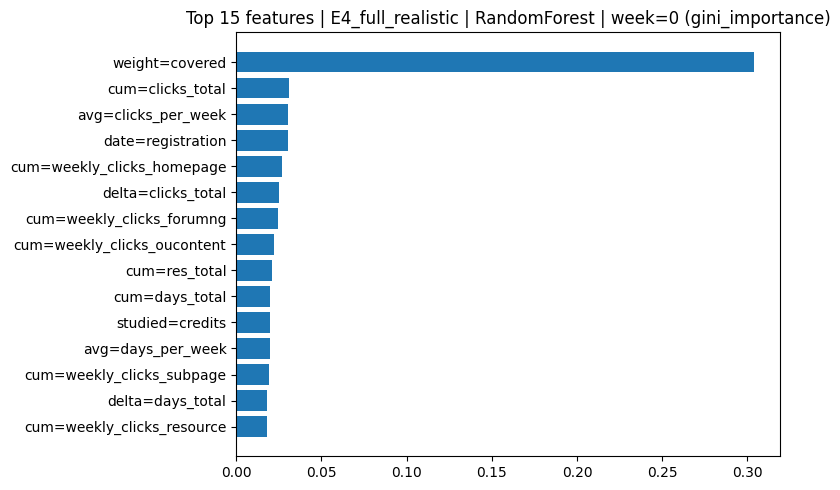

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week1__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week1_gini_importance.png


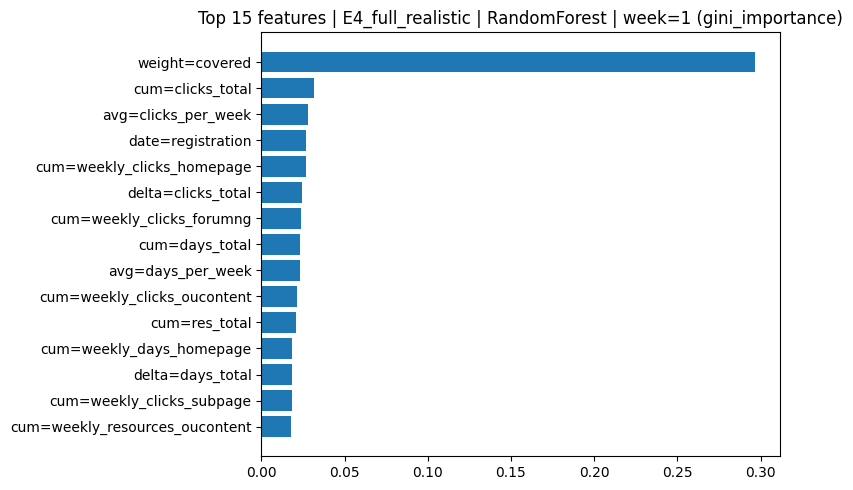

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week2__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week2_gini_importance.png


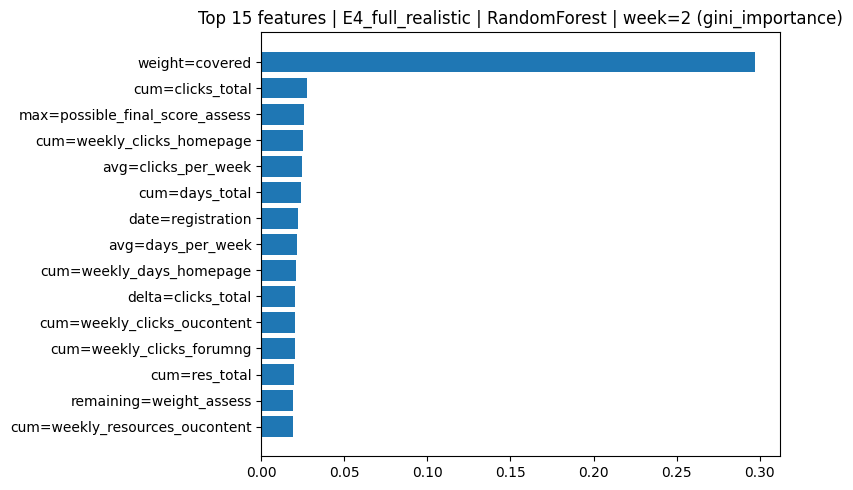

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week3__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week3_gini_importance.png


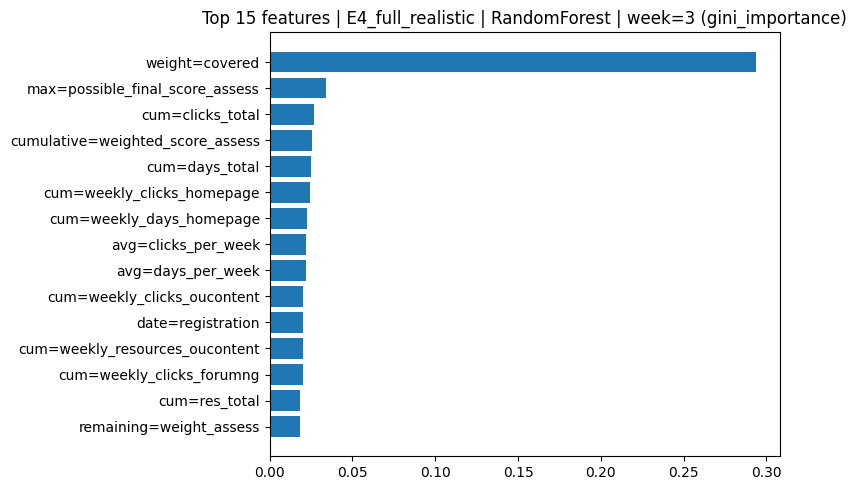

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week4__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week4_gini_importance.png


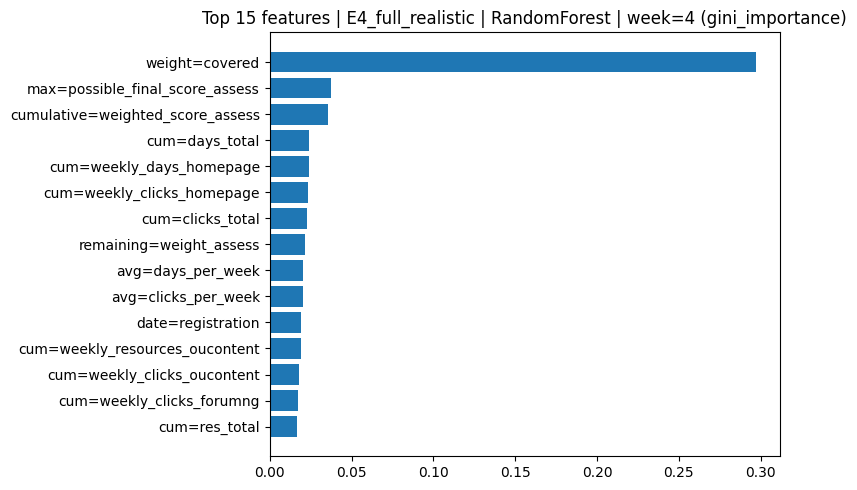

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week5__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week5_gini_importance.png


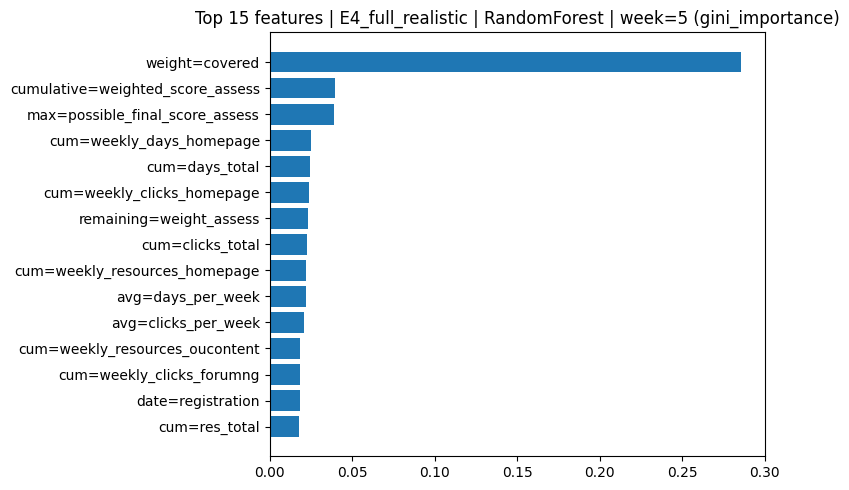

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week6__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week6_gini_importance.png


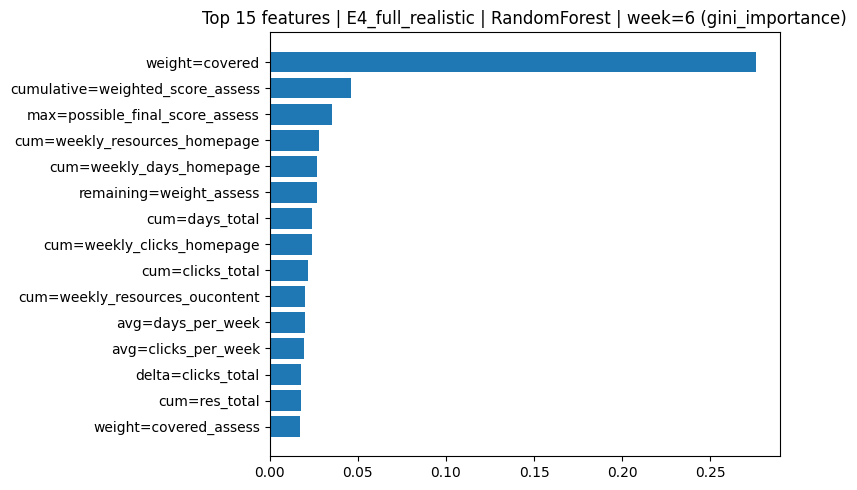

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week7__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week7_gini_importance.png


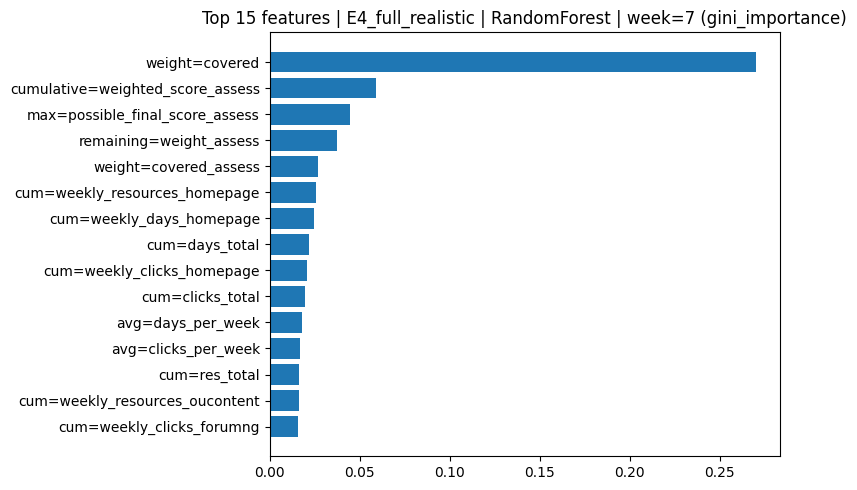

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week8__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week8_gini_importance.png


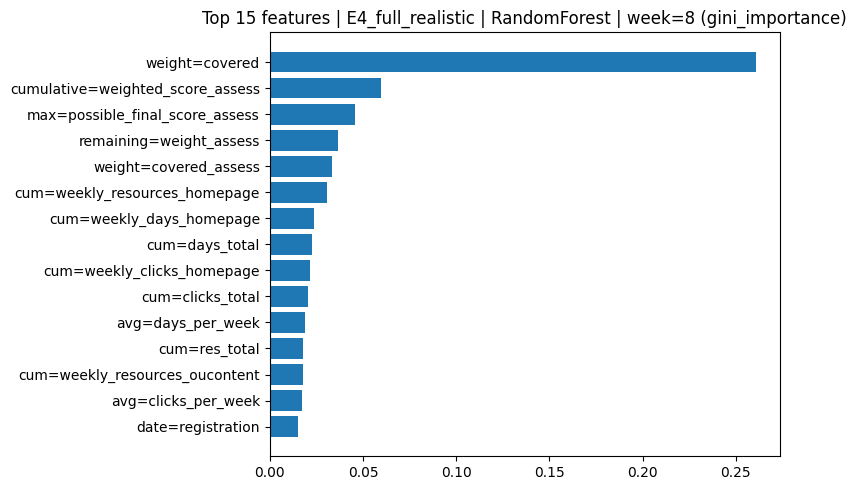

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week9__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week9_gini_importance.png


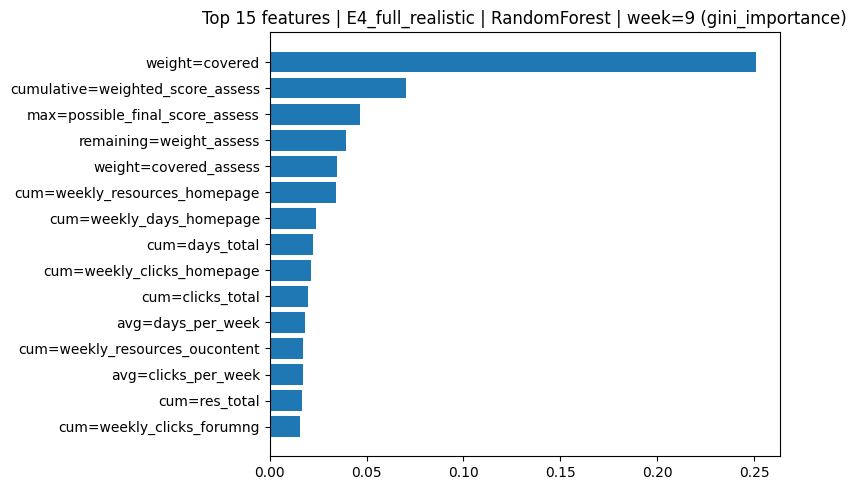

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week10__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week10_gini_importance.png


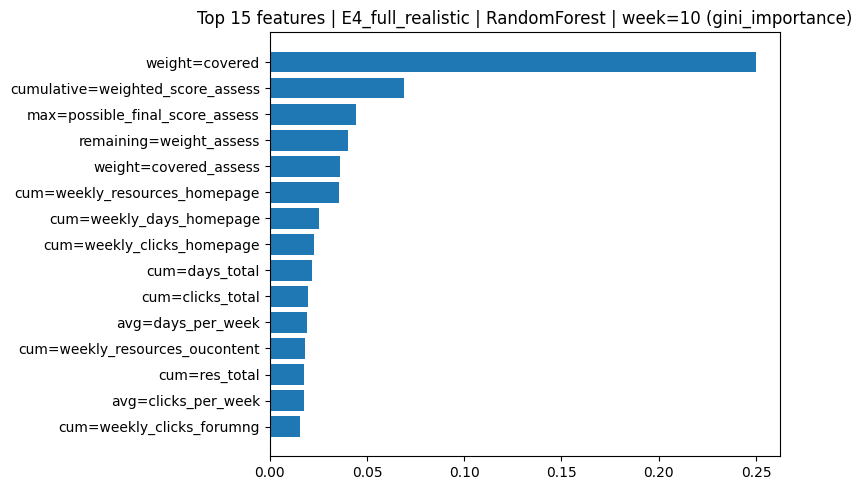

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week11__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week11_gini_importance.png


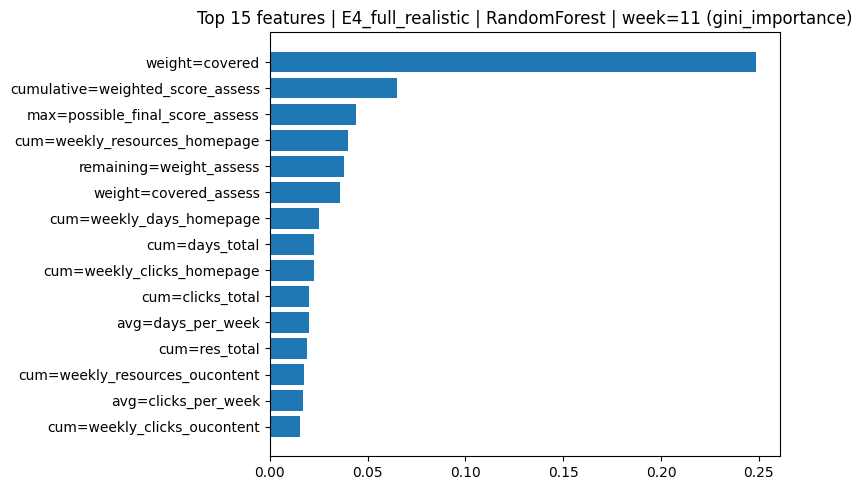

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week12__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week12_gini_importance.png


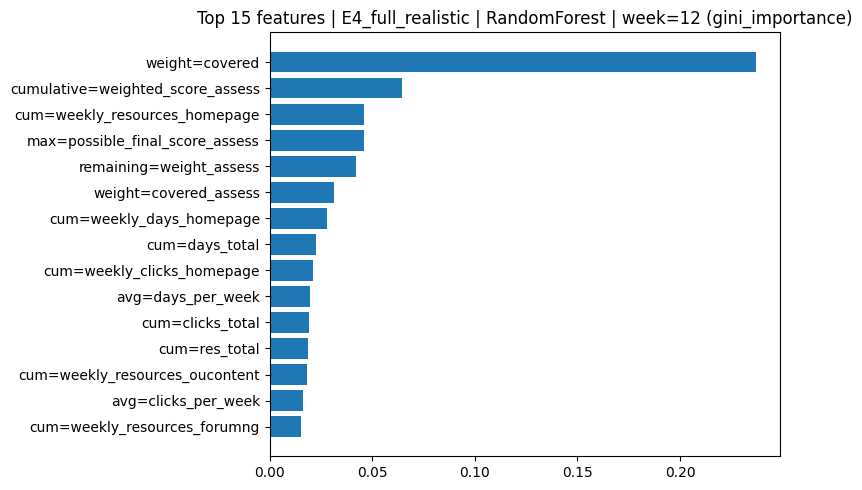

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week13__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week13_gini_importance.png


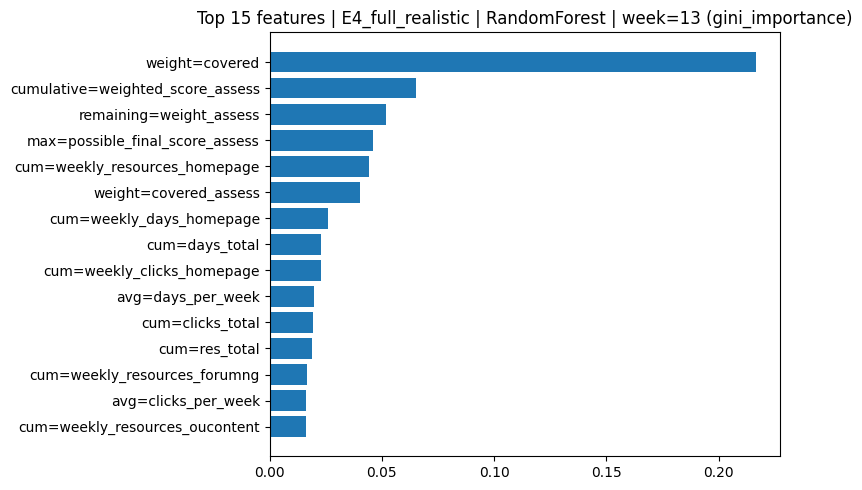

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week14__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week14_gini_importance.png


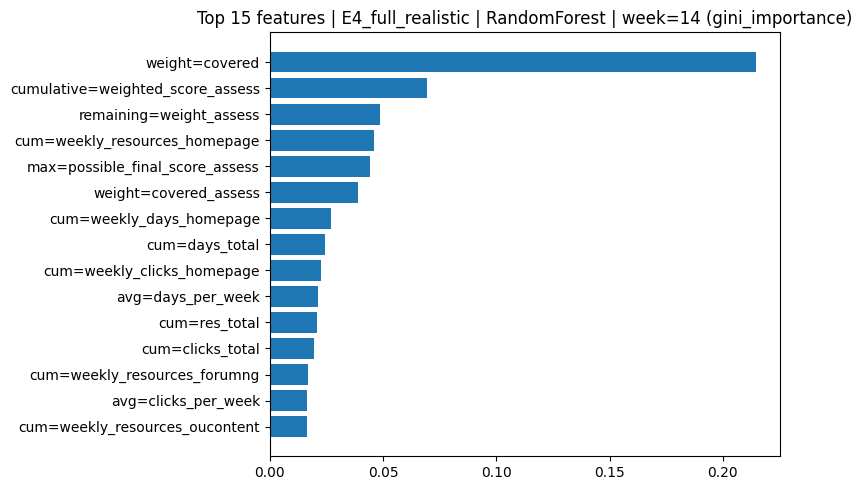

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week15__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week15_gini_importance.png


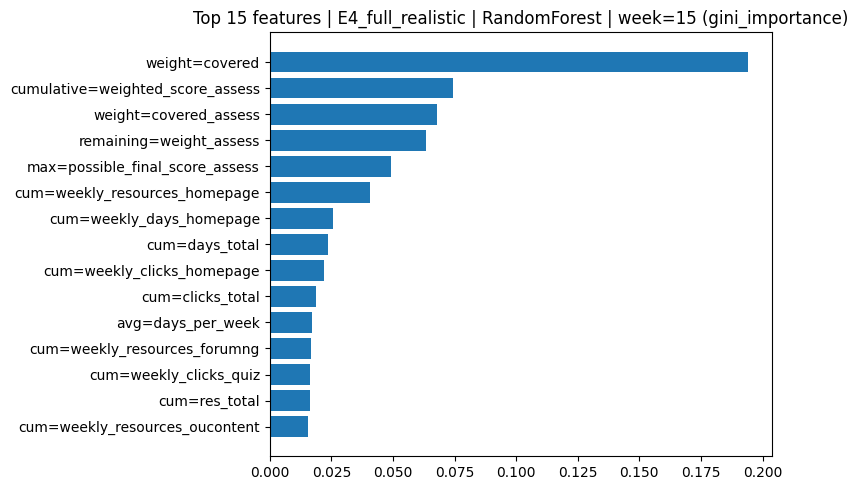

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week16__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week16_gini_importance.png


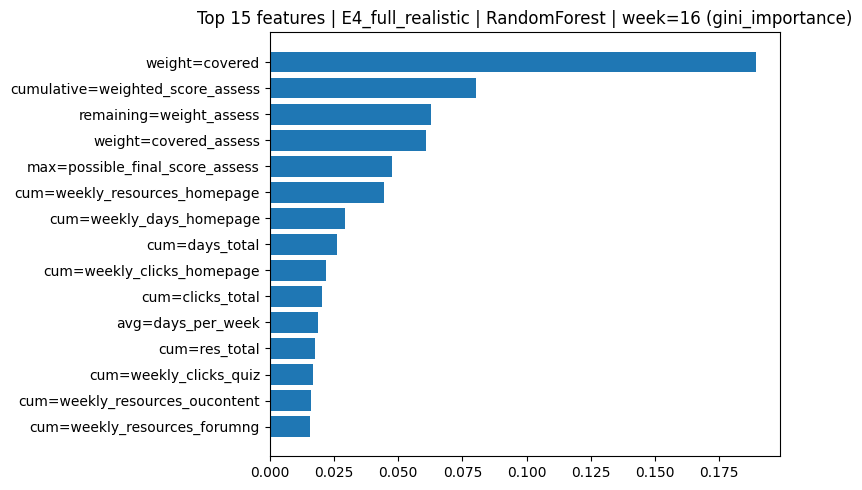

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week17__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week17_gini_importance.png


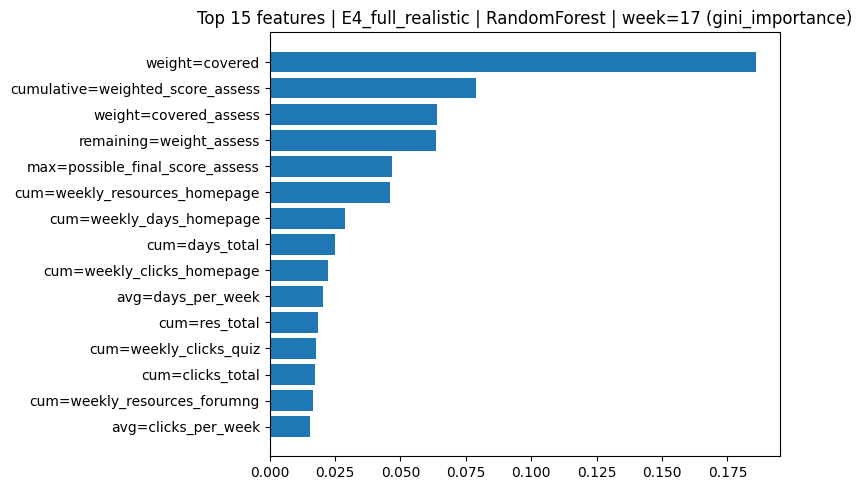

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week18__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week18_gini_importance.png


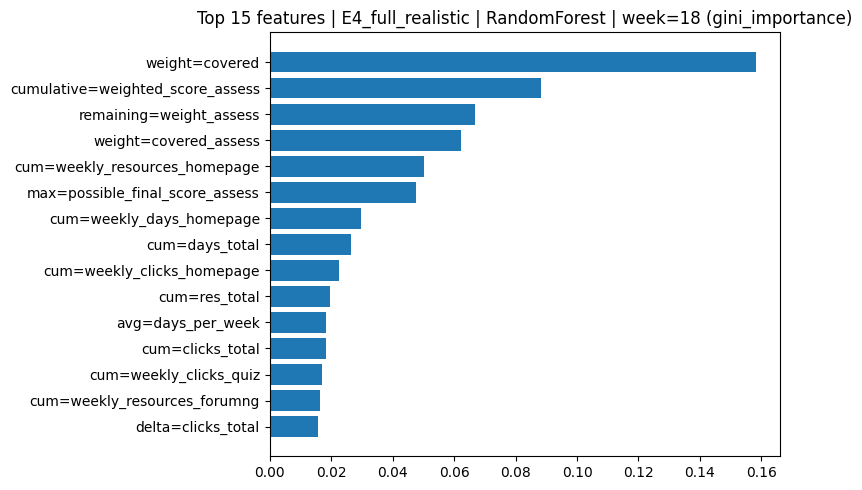

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week19__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week19_gini_importance.png


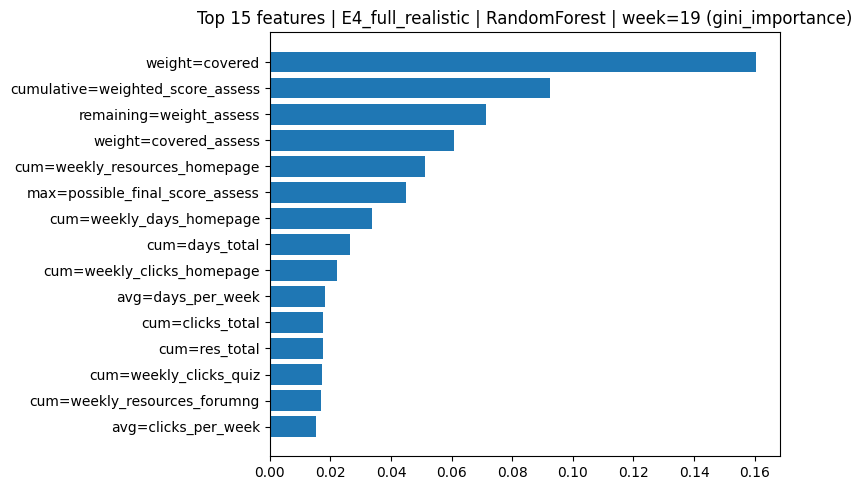

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week20__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week20_gini_importance.png


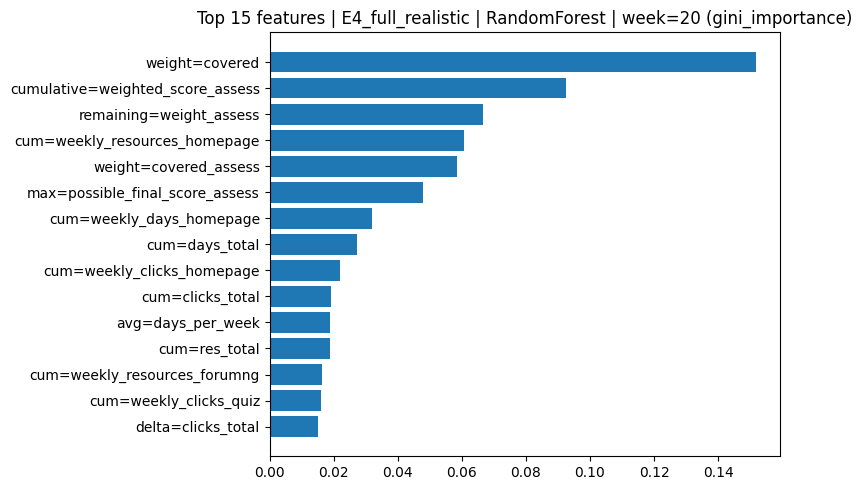

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week21__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week21_gini_importance.png


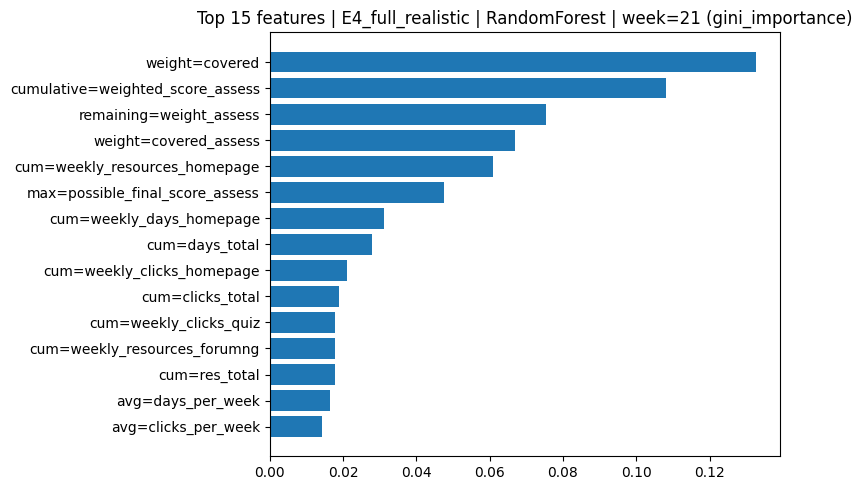

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week22__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week22_gini_importance.png


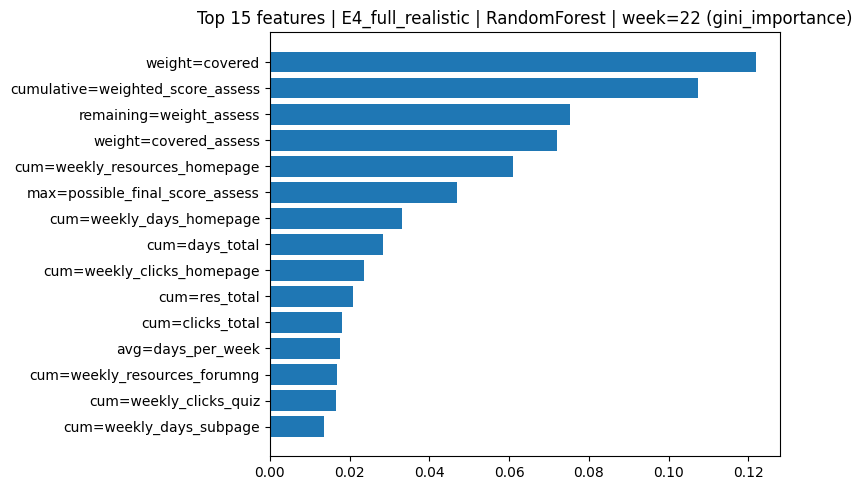

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week23__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week23_gini_importance.png


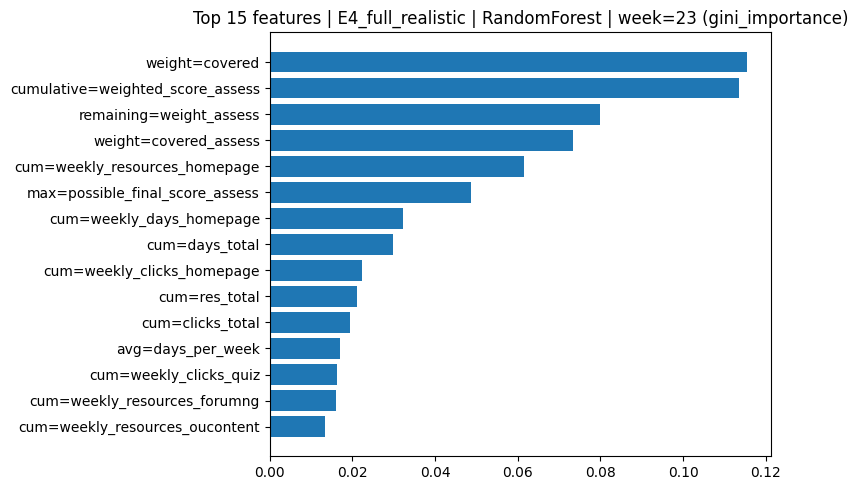

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week24__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week24_gini_importance.png


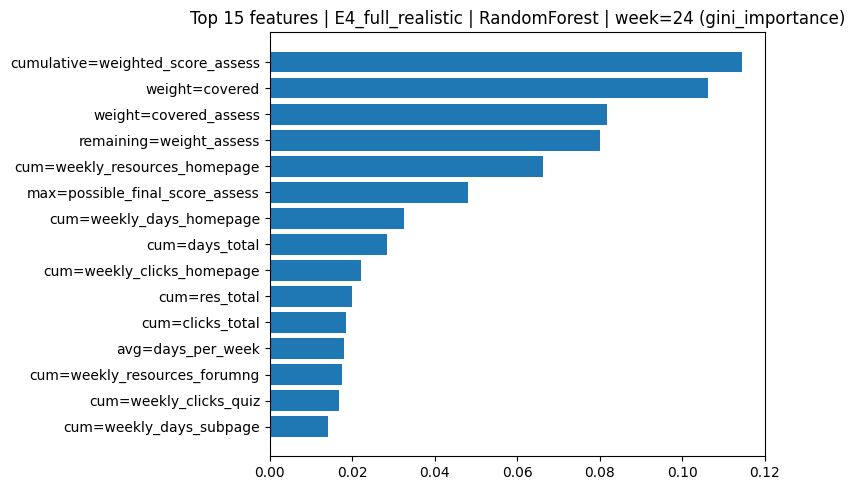

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week25__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week25_gini_importance.png


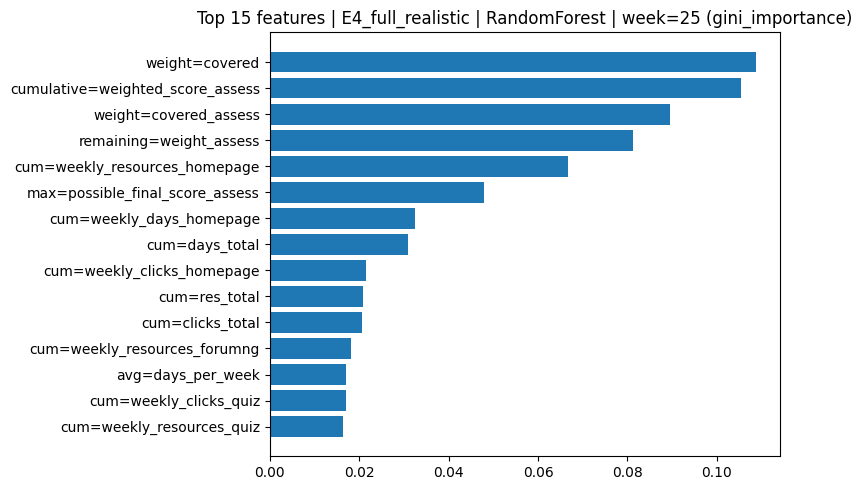

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week26__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week26_gini_importance.png


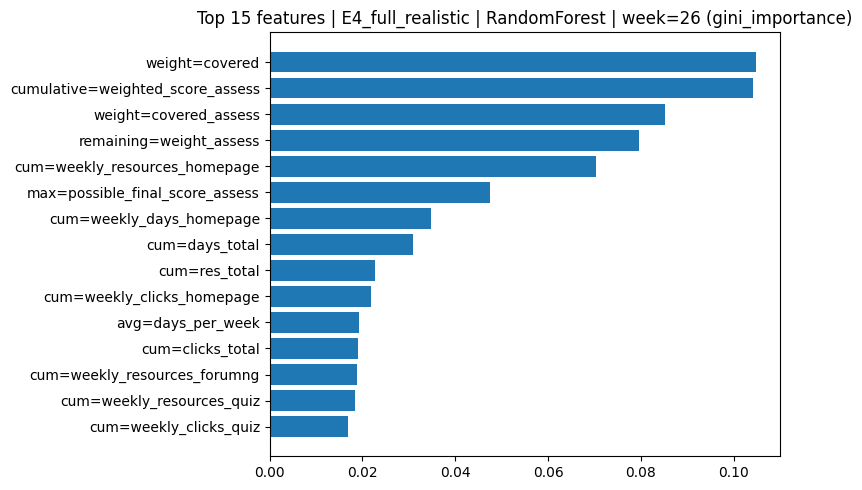

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week27__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week27_gini_importance.png


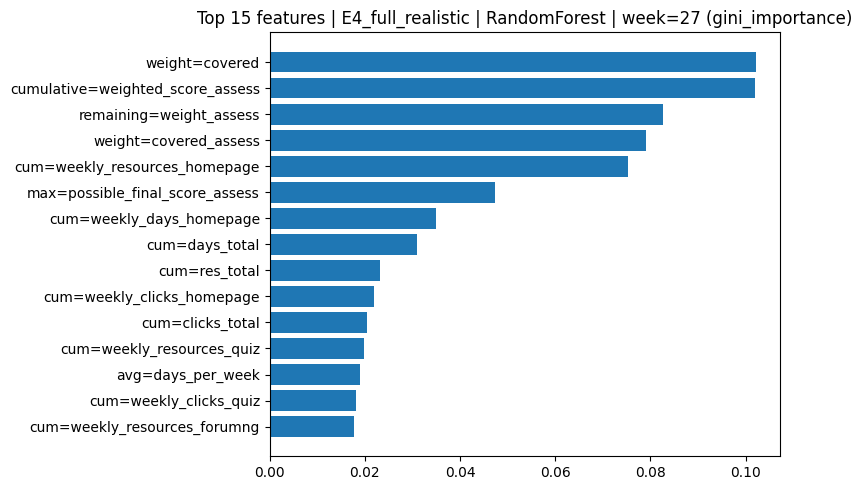

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week28__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week28_gini_importance.png


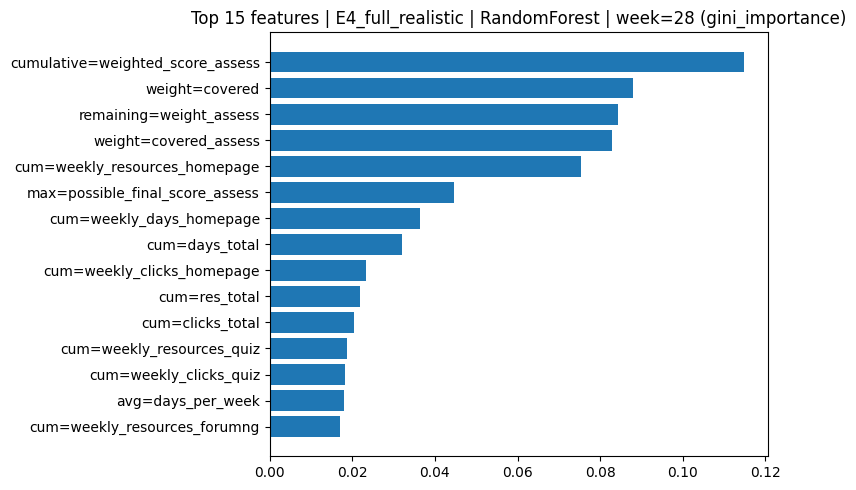

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week29__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week29_gini_importance.png


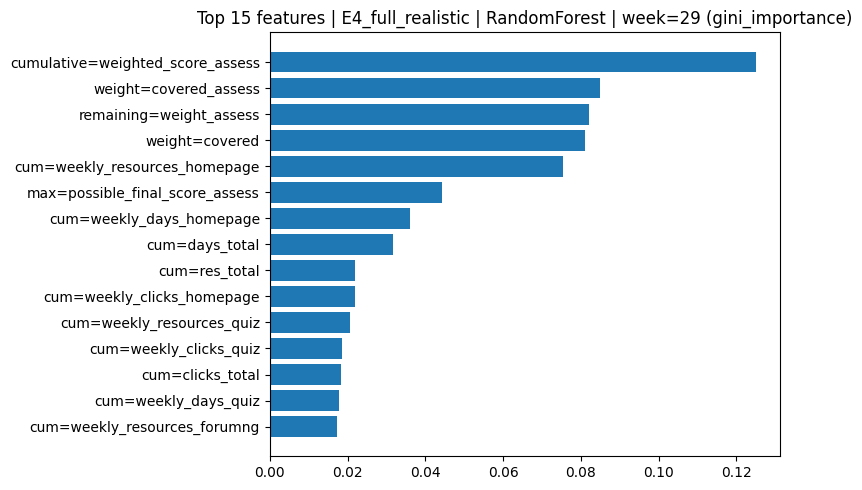

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week30__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week30_gini_importance.png


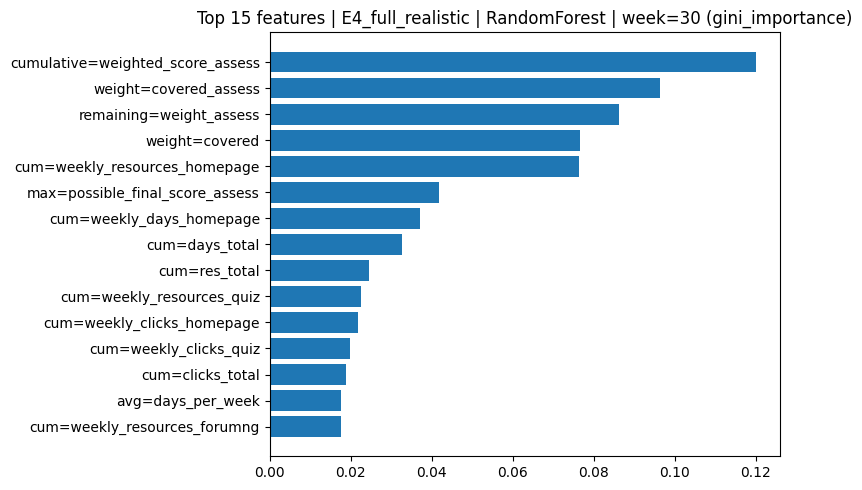

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week31__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week31_gini_importance.png


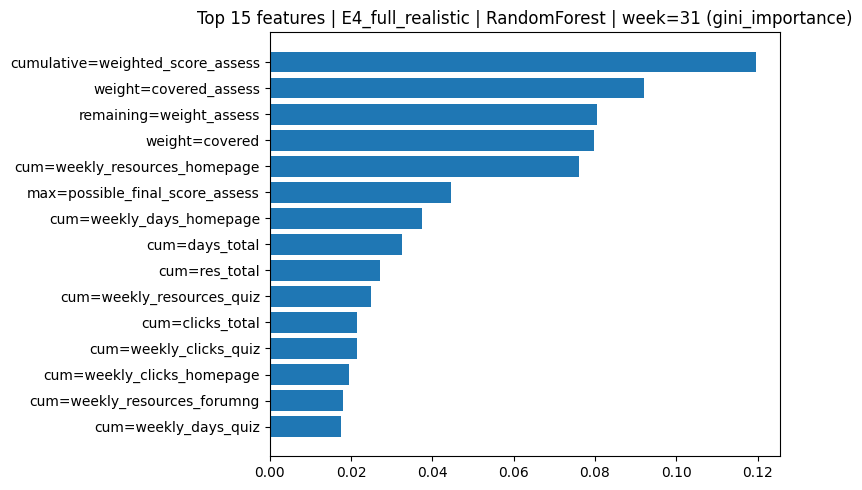

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week32__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week32_gini_importance.png


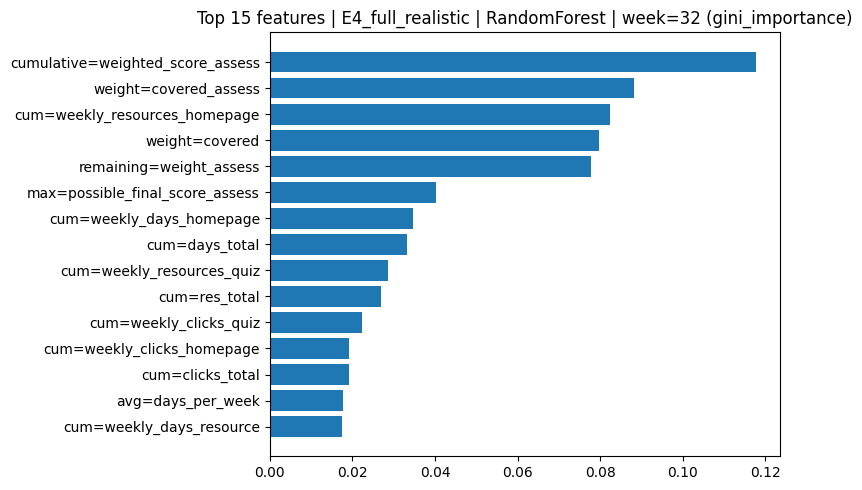

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week33__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week33_gini_importance.png


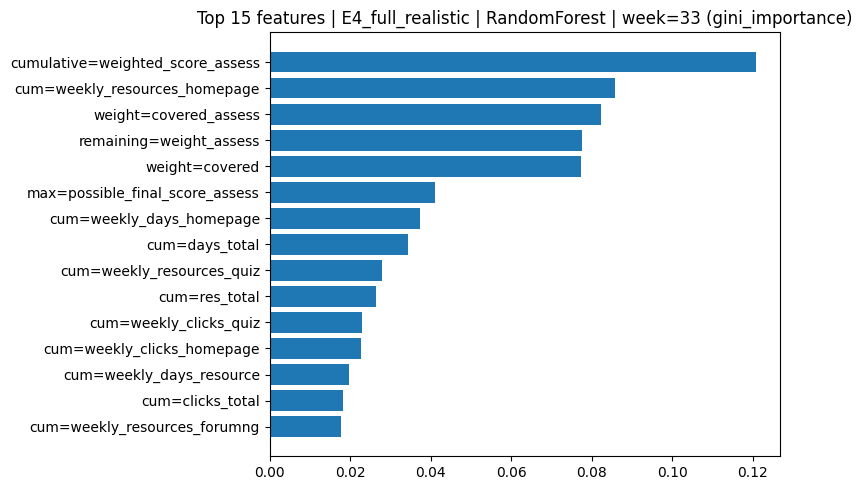

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week34__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week34_gini_importance.png


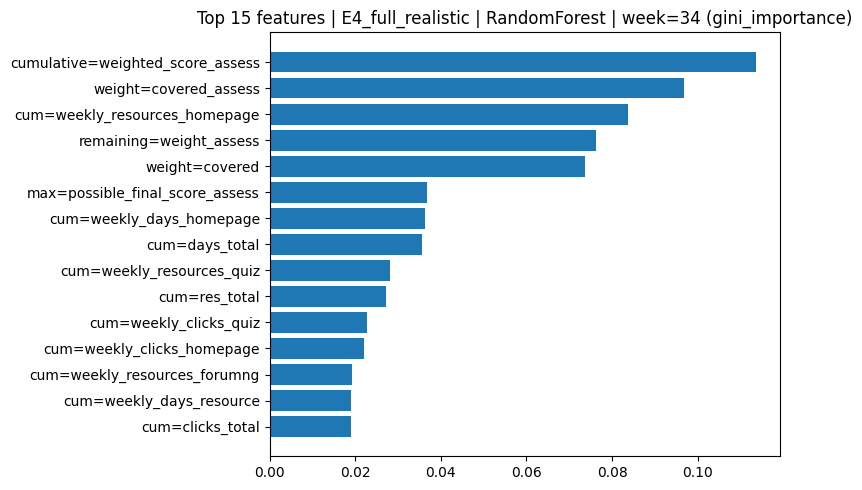

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week35__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week35_gini_importance.png


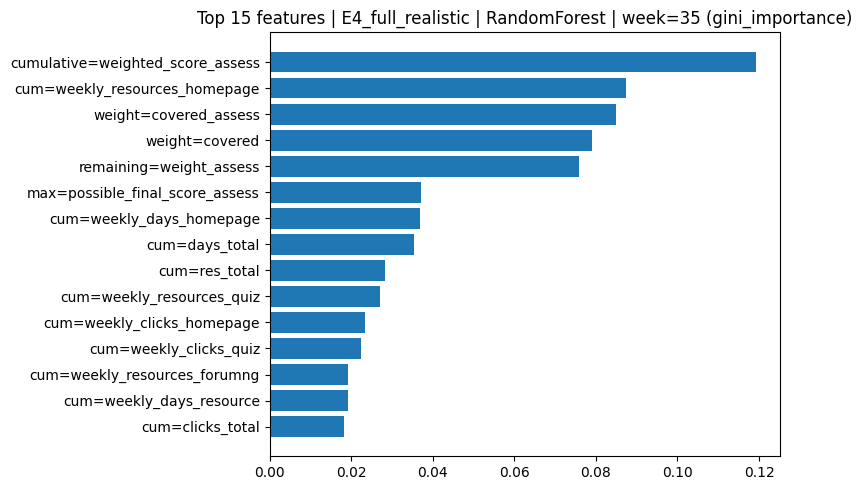

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week36__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week36_gini_importance.png


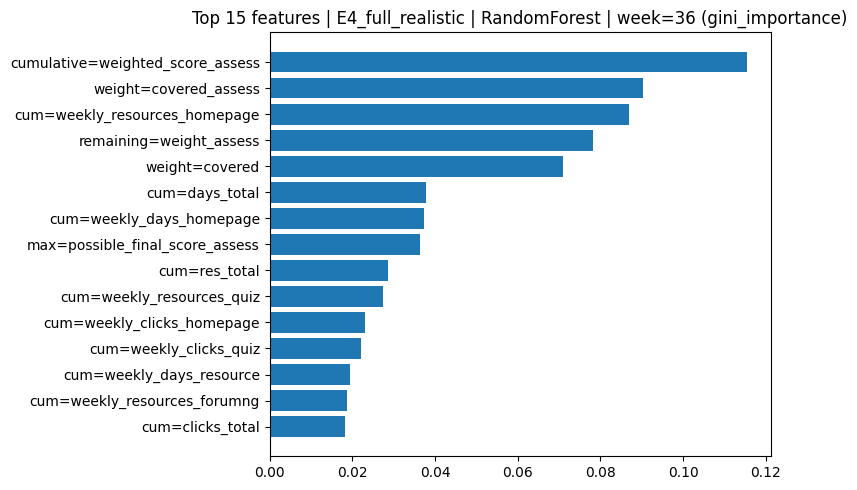

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week37__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week37_gini_importance.png


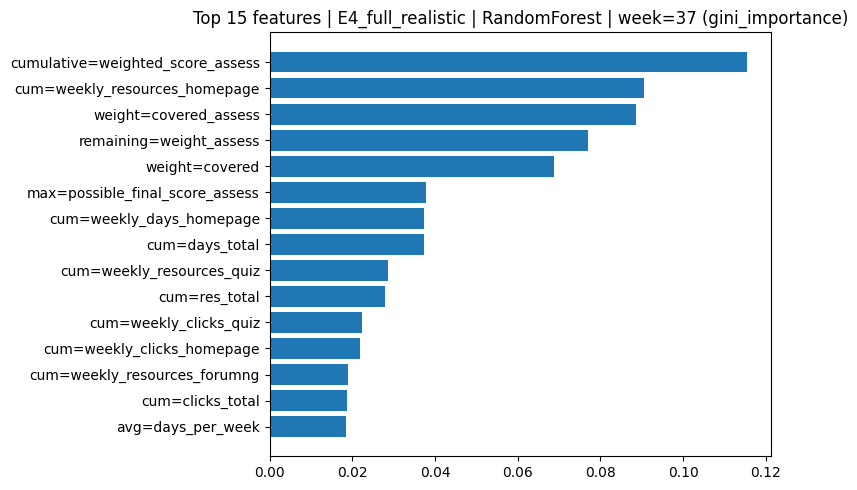

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/top_features__E4_full_realistic__RandomForest__week38__gini_importance.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/top_features_E4_full_realistic_RandomForest_week38_gini_importance.png


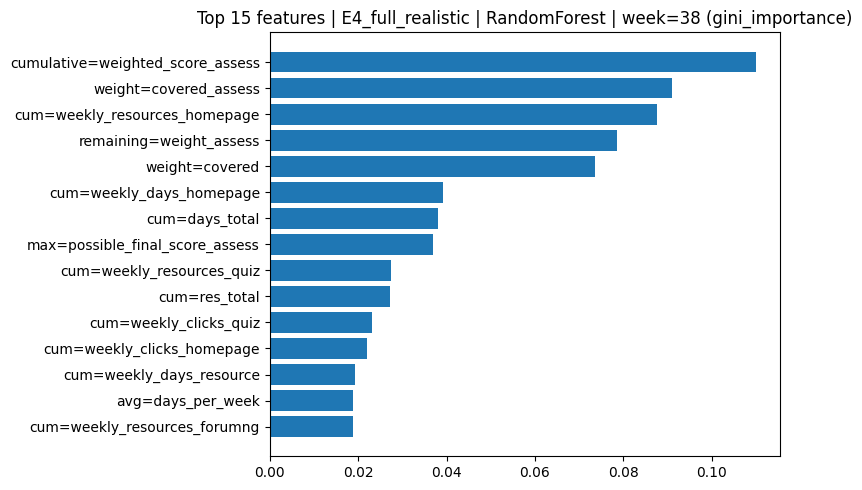

Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/feature_importance_over_time__E4_full_realistic__RandomForest__every1w.csv


,feature,importance,week_t,experiment,model,method
0,weight=covered,0.303948,0,E4_full_realistic,RandomForest,gini_importance
1,cum=clicks_total,0.030816,0,E4_full_realistic,RandomForest,gini_importance
2,avg=clicks_per_week,0.030338,0,E4_full_realistic,RandomForest,gini_importance
3,date=registration,0.030234,0,E4_full_realistic,RandomForest,gini_importance
4,cum=weekly_clicks_homepage,0.026868,0,E4_full_realistic,RandomForest,gini_importance


In [9]:
# ------------------------------------------------------------
# Top features every t weeks
# ------------------------------------------------------------
exp_name = "E4_full_realistic"      # change if needed
model_name = "RandomForest"         # "LogReg" or "RandomForest"
top_n = 15
step = 1

drop_cols = experiments[exp_name]["drop_cols"]
model = models[model_name]

weeks_available = sorted([int(w) for w in df["week"].dropna().unique() if int(w) >= 0])
weeks_slices = [w for w in range(0, max(weeks_available) + 1, step) if w in set(weeks_available)]

def get_feature_names(prep: ColumnTransformer) -> np.ndarray:
    """
    Robust: matches the transformed matrix column order.
    Returns cleaner names (no num__/cat__ prefixes).
    """
    names = prep.get_feature_names_out()
    names = np.array([n.replace("num__", "").replace("cat__", "") for n in names])

    # Optional: nicer one-hot display: gender_M -> gender=M
    pretty = []
    for n in names:
        if "_" in n:
            col, level = n.split("_", 1)
            pretty.append(f"{col}={level}")
        else:
            pretty.append(n)
    return np.array(pretty)

all_importances = []

for t in weeks_slices:
    pipe, X_test, y_test, y_pred, proba = fit_predict_week(df, t, model, drop_cols=drop_cols)

    prep = pipe.named_steps["prep"]
    feature_names = get_feature_names(prep)

    if model_name == "LogReg":
        values = np.abs(pipe.named_steps["model"].coef_.ravel())
        method = "abs_coef"
    elif model_name == "RandomForest":
        values = pipe.named_steps["model"].feature_importances_
        method = "gini_importance"
    else:
        raise ValueError(f"Unsupported model_name: {model_name}")

    imp_df = (
        pd.DataFrame({"feature": feature_names, "importance": values})
          .sort_values("importance", ascending=False)
          .head(top_n)
          .reset_index(drop=True)
    )
    imp_df["week_t"] = t
    imp_df["experiment"] = exp_name
    imp_df["model"] = model_name
    imp_df["method"] = method

    all_importances.append(imp_df)

    # ---- Save per-week CSV
    csv_path = FEAT_DIR / f"top_features__{exp_name}__{model_name}__week{t}__{method}.csv"
    imp_df.to_csv(csv_path, index=False)
    print("Saved:", csv_path)

    # ---- Plot per-week
    plt.figure(figsize=(8, 5))
    plt.barh(imp_df["feature"][::-1], imp_df["importance"][::-1])
    plt.title(f"Top {top_n} features | {exp_name} | {model_name} | week={t} ({method})")
    plt.tight_layout()
    savefig(f"top_features__{exp_name}__{model_name}__week{t}__{method}")
    plt.show()

# ---- Save long-form importance table (like regressor’s all_importances)
fi_long = pd.concat(all_importances, ignore_index=True)
fi_long_path = FEAT_DIR / f"feature_importance_over_time__{exp_name}__{model_name}__every{step}w.csv"
fi_long.to_csv(fi_long_path, index=False)
print("Saved:", fi_long_path)

fi_long.head()


In [10]:
exp_name = "E4_full_realistic"
model_name = "RandomForest"
step = 5   # MUST match how it was saved

fi_long_path = FEAT_DIR / f"feature_importance_over_time__{exp_name}__{model_name}__every{step}w.csv"
fi_long = pd.read_csv(fi_long_path)

fi_wide = (
    fi_long.pivot_table(index="week_t", columns="feature", values="importance", aggfunc="mean")
           .reset_index()
)

fi_wide_path = FEAT_DIR / f"feature_importance_pivot__{exp_name}__{model_name}__every{step}w.csv"
fi_wide.to_csv(fi_wide_path, index=False)
print("Saved:", fi_wide_path)


Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/feature_importance_pivot__E4_full_realistic__RandomForest__every5w.csv


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/feature_importance_lines_E4_full_realistic_RandomForest_top10.png


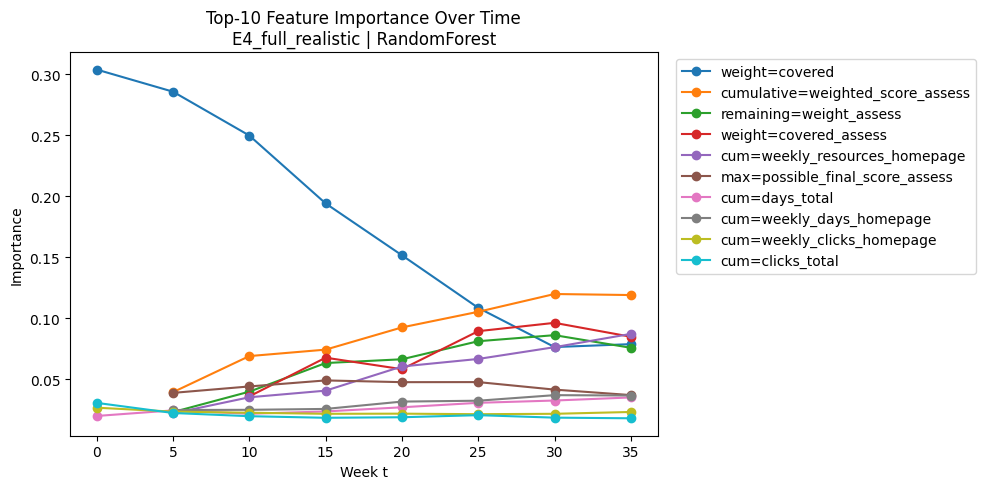

In [11]:
exp_name = "E4_full_realistic"
model_name = "RandomForest"
top_k = 10

fi_wide_path = FEAT_DIR / f"feature_importance_pivot__{exp_name}__{model_name}__every5w.csv"
fi_wide = pd.read_csv(fi_wide_path)

fi_wide = fi_wide.sort_values("week_t").reset_index(drop=True)

feature_cols = [c for c in fi_wide.columns if c != "week_t"]

# Select top-K features globally
top_features = (
    fi_wide[feature_cols]
      .sum(axis=0, skipna=True)
      .sort_values(ascending=False)
      .head(top_k)
      .index
)

plt.figure(figsize=(10, 5))
for feat in top_features:
    plt.plot(
        fi_wide["week_t"],
        fi_wide[feat],
        marker="o",
        label=feat
    )

plt.title(f"Top-{top_k} Feature Importance Over Time\n{exp_name} | {model_name}")
plt.xlabel("Week t")
plt.ylabel("Importance")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
savefig(f"feature_importance_lines__{exp_name}__{model_name}__top{top_k}")
plt.show()

In [12]:
# Pivot: week × feature = importance (top features only)
fi_pivot = (
    fi_long.pivot_table(index="week_t", columns="feature", values="importance", aggfunc="first")
          .sort_index()
)

fi_pivot_path = FEAT_DIR / f"feature_importance_pivot__{exp_name}__{model_name}__every5w.csv"
fi_pivot.to_csv(fi_pivot_path)
print("Saved:", fi_pivot_path)

fi_pivot.head()

Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/features/feature_importance_pivot__E4_full_realistic__RandomForest__every5w.csv


feature,avg=clicks_per_week,avg=days_per_week,cum=clicks_total,cum=days_total,cum=res_total,cum=weekly_clicks_forumng,cum=weekly_clicks_homepage,cum=weekly_clicks_oucontent,cum=weekly_clicks_quiz,cum=weekly_clicks_resource,...,cum=weekly_resources_quiz,cumulative=weighted_score_assess,date=registration,delta=clicks_total,delta=days_total,max=possible_final_score_assess,remaining=weight_assess,studied=credits,weight=covered,weight=covered_assess
week_t,,,,,,,,,,,,,,,,,,,,,
0,0.030338,0.019983,0.030816,0.020094,0.021056,0.024535,0.026868,0.022383,NaN,0.017848,...,NaN,NaN,0.030234,0.025106,0.018318,NaN,NaN,0.020075,0.303948,NaN
5,0.020689,0.021971,0.022526,0.024670,0.018024,0.018387,0.023649,NaN,NaN,NaN,...,NaN,0.039611,0.018081,NaN,NaN,0.039014,0.023275,NaN,0.285809,NaN
10,0.017403,0.019337,0.019911,0.021899,0.017847,0.015468,0.022740,NaN,NaN,NaN,...,NaN,0.069163,NaN,NaN,NaN,0.044285,0.040006,NaN,0.249874,0.036141
15,NaN,0.017328,0.018601,0.023795,0.016180,NaN,0.021860,NaN,0.016527,NaN,...,NaN,0.074456,NaN,NaN,NaN,0.049220,0.063472,NaN,0.194247,0.067854
20,NaN,0.018851,0.019045,0.027208,0.018787,NaN,0.021978,NaN,0.016065,NaN,...,NaN,0.092665,NaN,0.015099,NaN,0.047792,0.066546,NaN,0.151757,0.058424


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week0.png


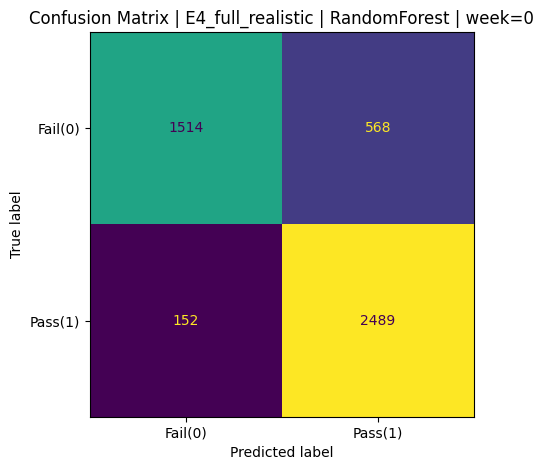

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week1.png


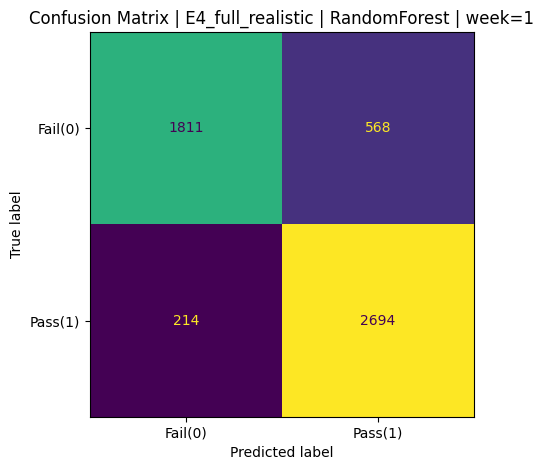

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week2.png


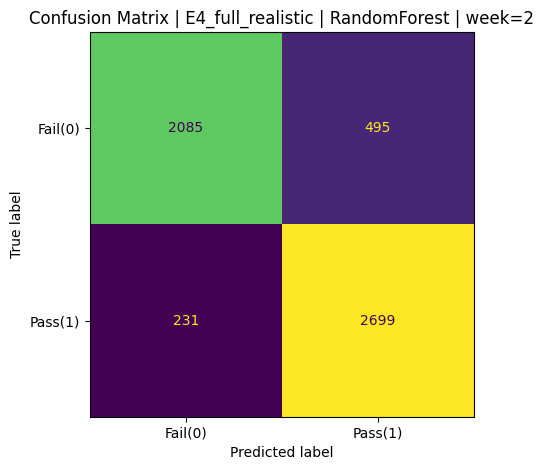

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week3.png


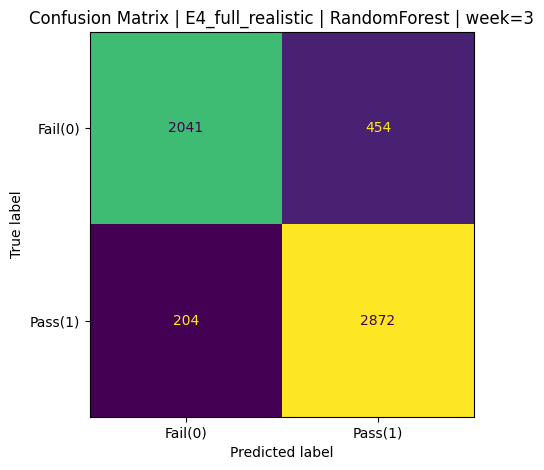

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week4.png


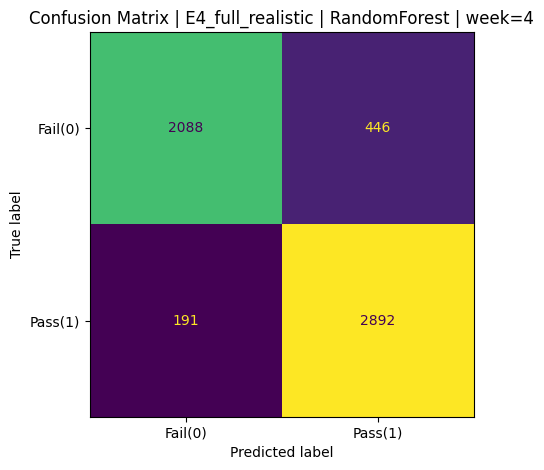

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week5.png


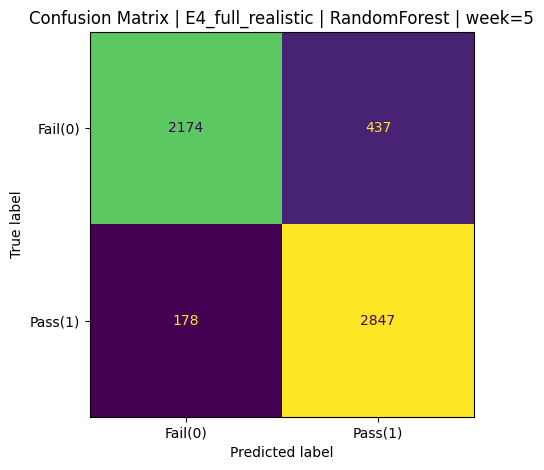

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week6.png


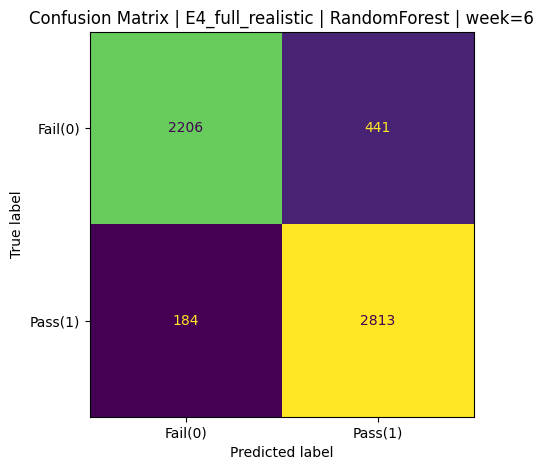

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week7.png


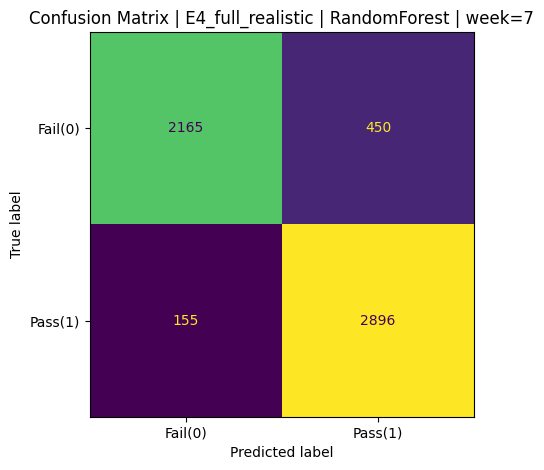

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week8.png


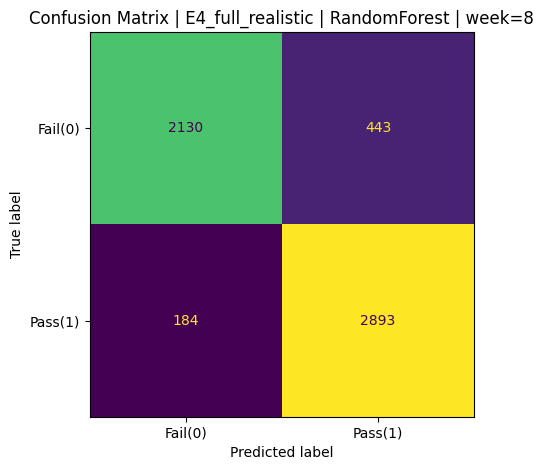

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week9.png


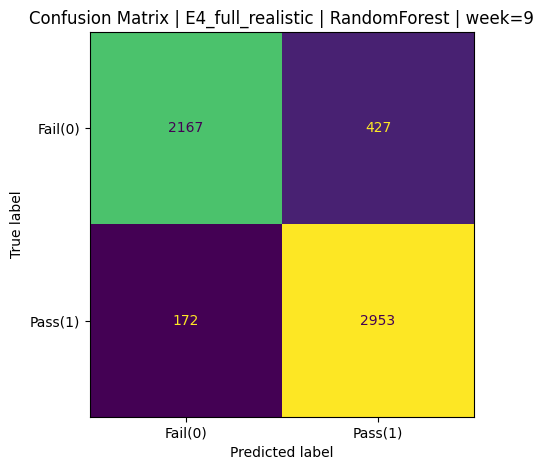

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week10.png


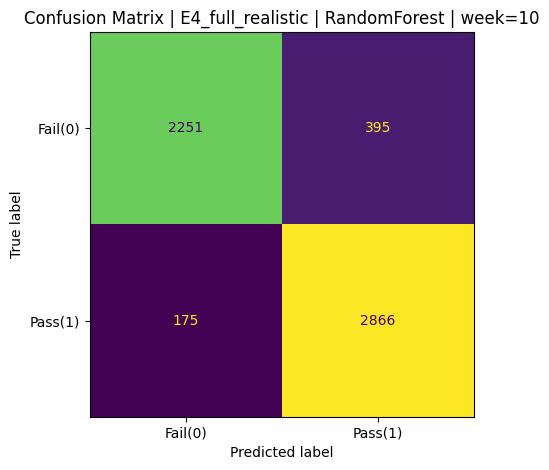

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week11.png


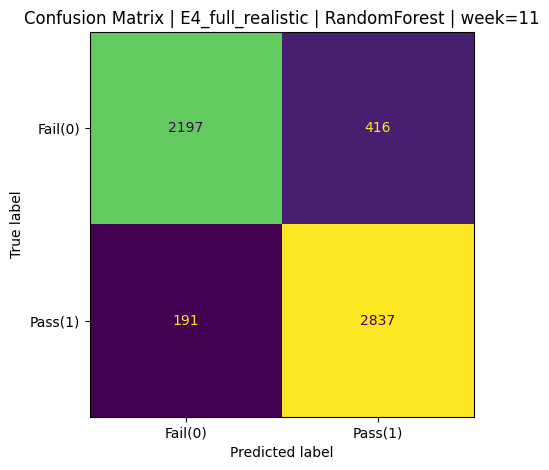

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week12.png


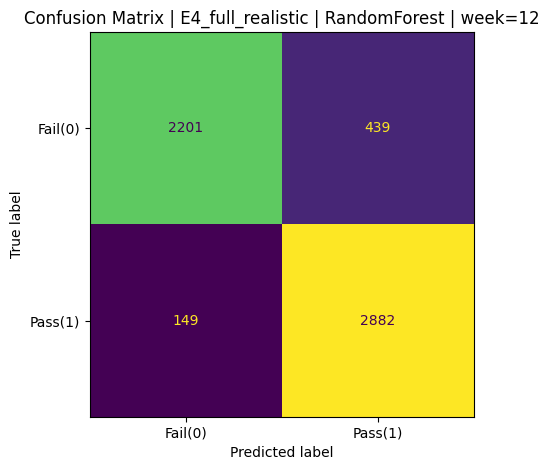

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week13.png


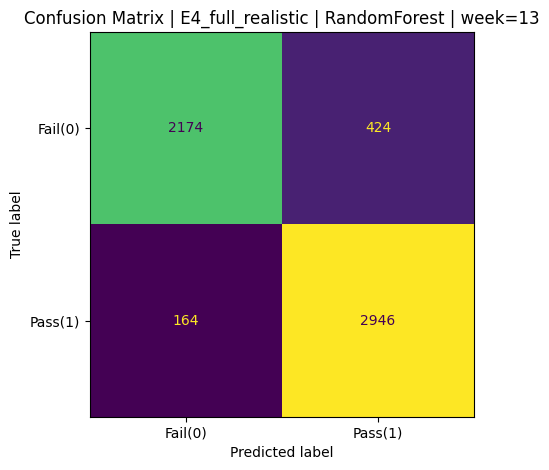

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week14.png


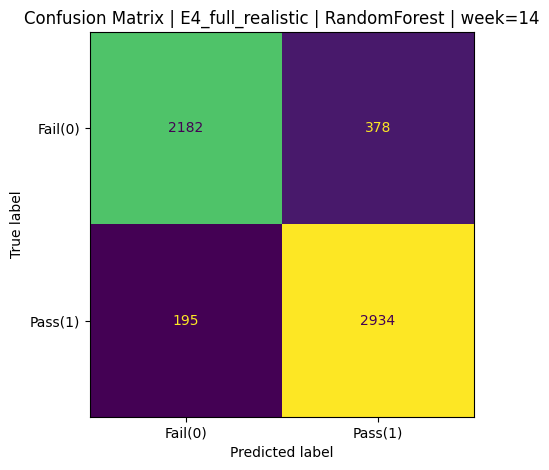

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week15.png


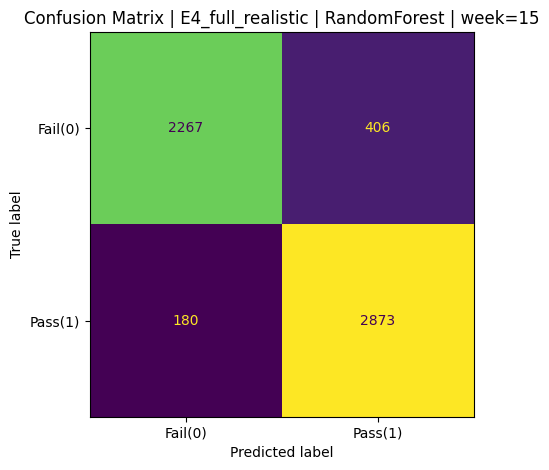

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week16.png


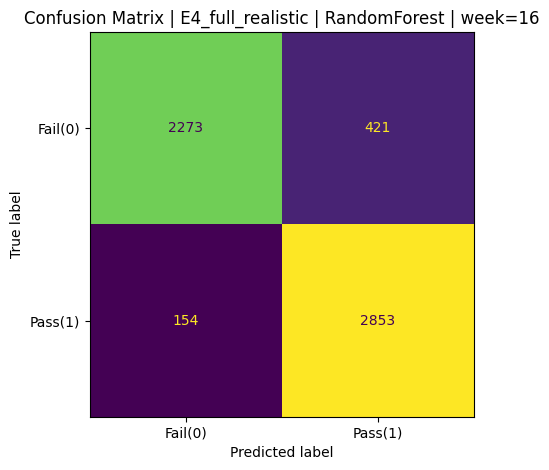

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week17.png


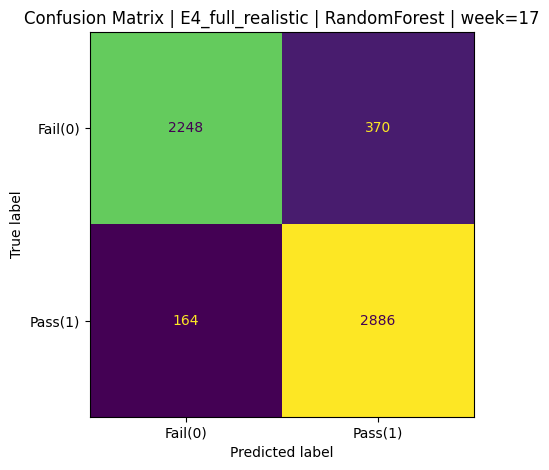

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week18.png


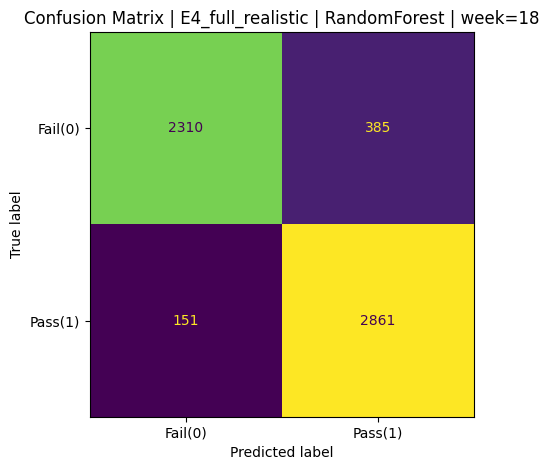

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week19.png


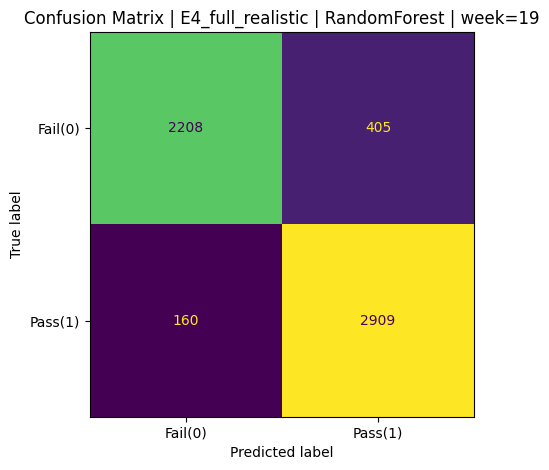

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week20.png


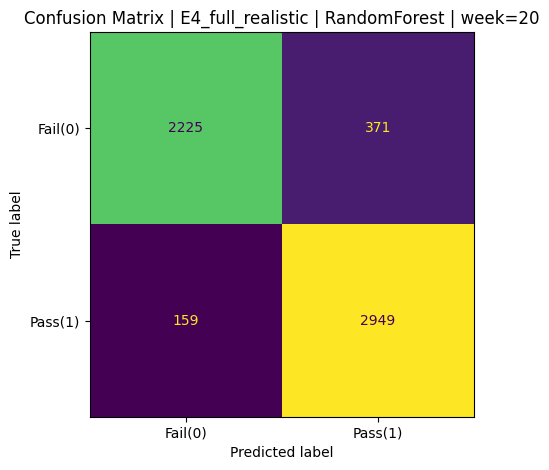

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week21.png


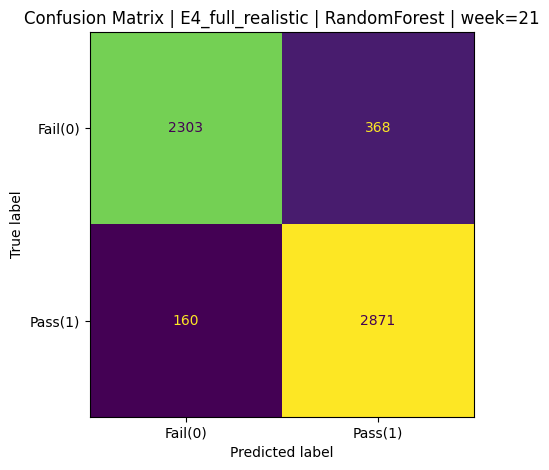

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week22.png


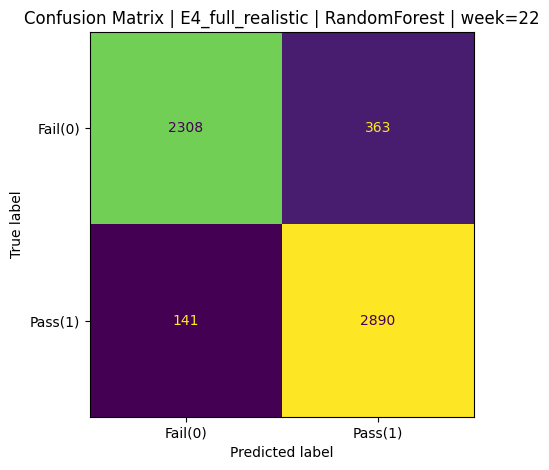

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week23.png


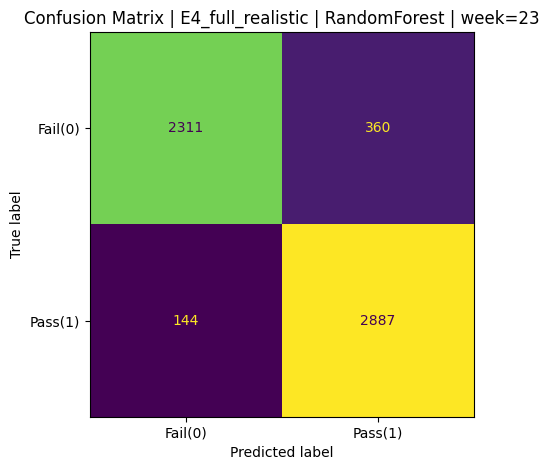

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week24.png


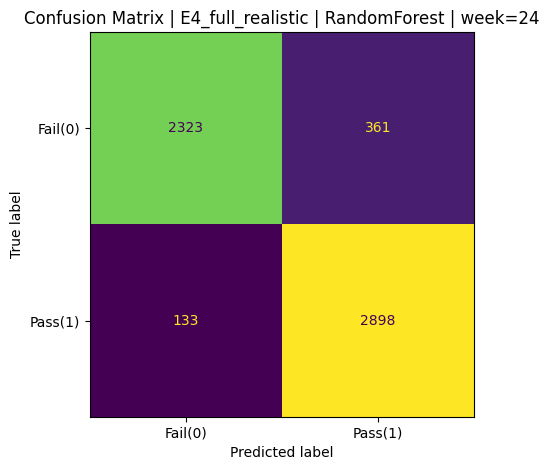

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week25.png


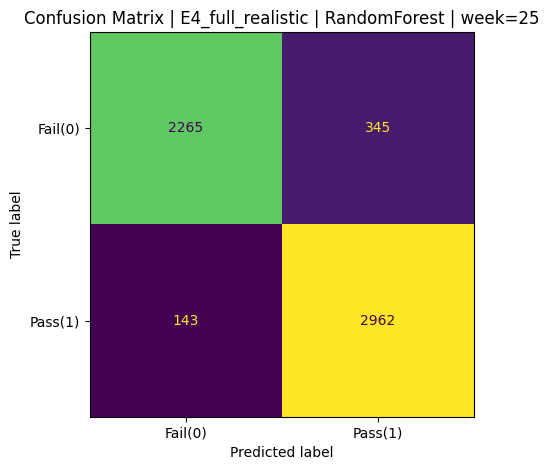

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week26.png


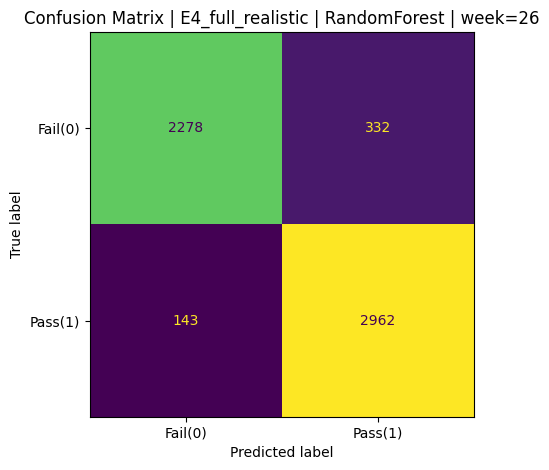

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week27.png


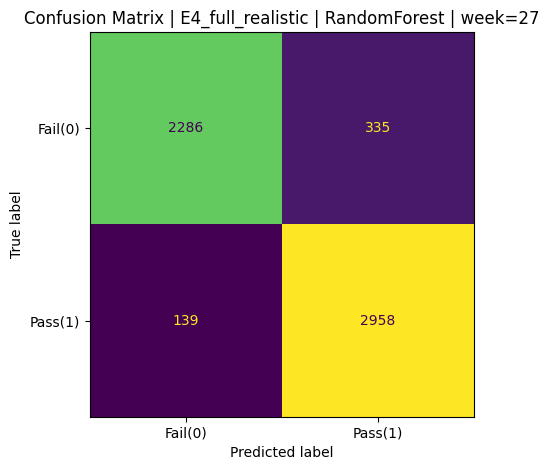

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week28.png


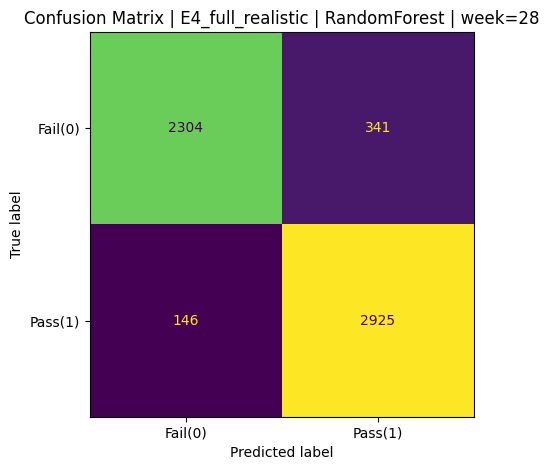

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week29.png


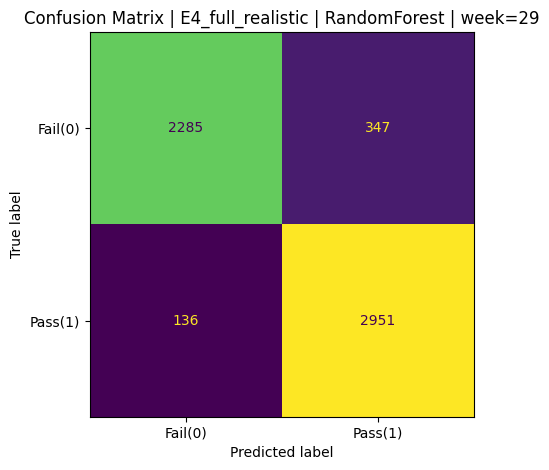

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week30.png


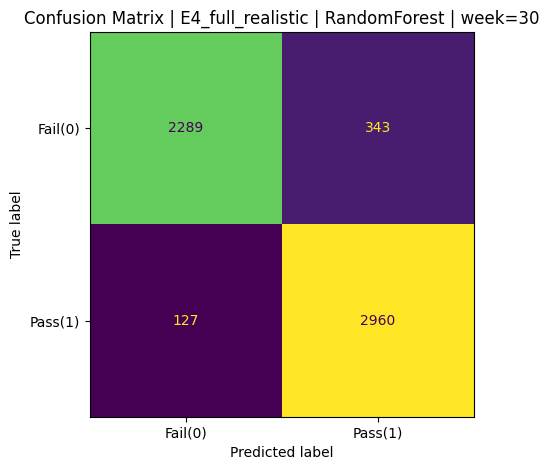

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week31.png


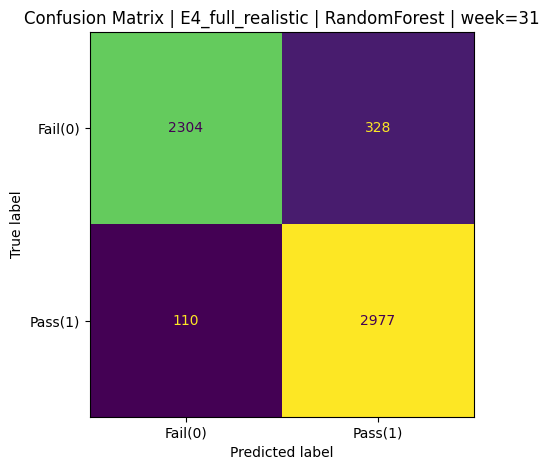

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week32.png


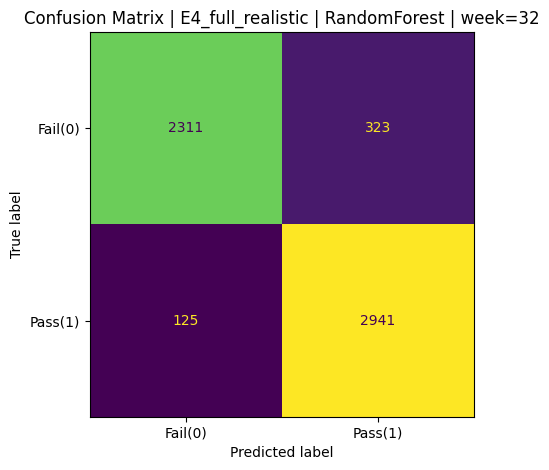

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week33.png


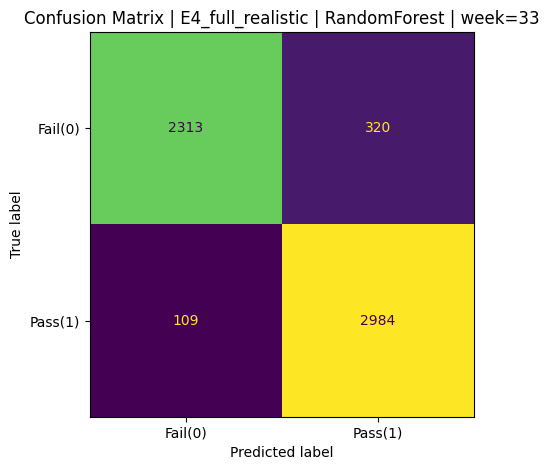

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week34.png


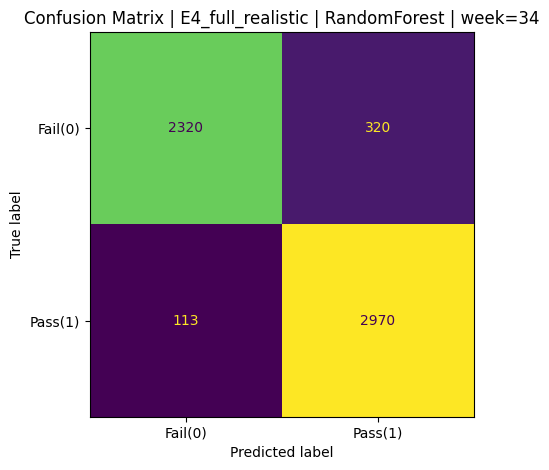

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week35.png


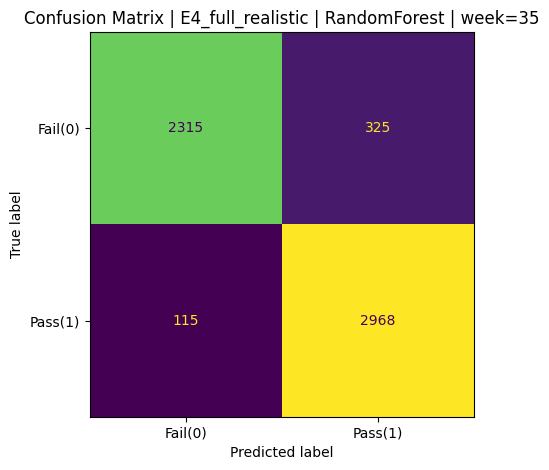

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week36.png


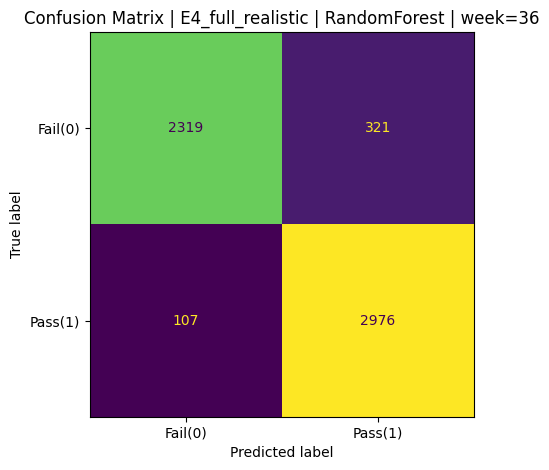

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week37.png


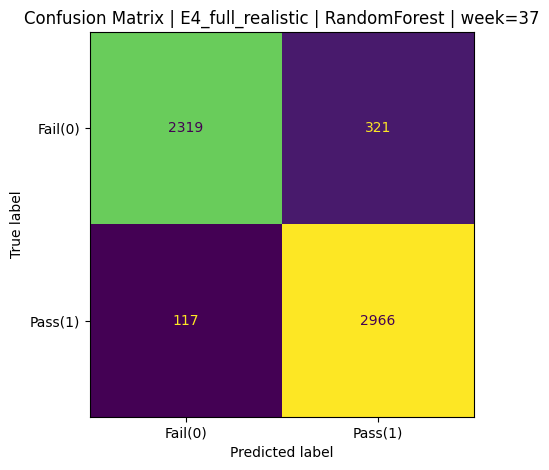

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_78449/1773587942.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/cm_E4_full_realistic_RandomForest_week38.png


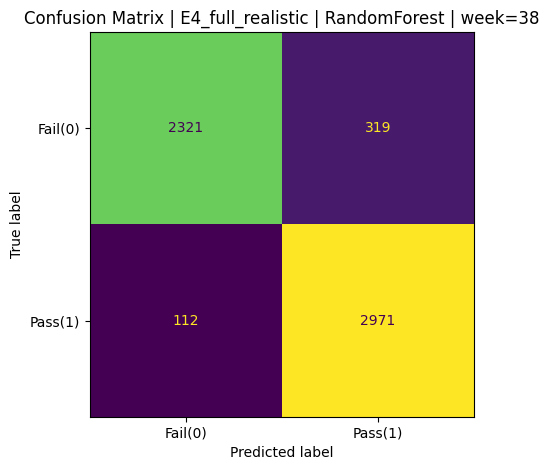

Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/tables/confusion_matrices_over_time__E4_full_realistic__RandomForest__every1w.csv


,week_t,experiment,model,tn,fp,fn,tp,n_test
0,0,E4_full_realistic,RandomForest,1514,568,152,2489,4723
1,1,E4_full_realistic,RandomForest,1811,568,214,2694,5287
2,2,E4_full_realistic,RandomForest,2085,495,231,2699,5510
3,3,E4_full_realistic,RandomForest,2041,454,204,2872,5571
4,4,E4_full_realistic,RandomForest,2088,446,191,2892,5617
5,5,E4_full_realistic,RandomForest,2174,437,178,2847,5636
6,6,E4_full_realistic,RandomForest,2206,441,184,2813,5644
7,7,E4_full_realistic,RandomForest,2165,450,155,2896,5666
8,8,E4_full_realistic,RandomForest,2130,443,184,2893,5650
9,9,E4_full_realistic,RandomForest,2167,427,172,2953,5719


In [13]:
# ------------------------------------------------------------
# Confusion matrices every t weeks 
# ------------------------------------------------------------
exp_name = "E4_full_realistic"      # change if needed
model_name = "RandomForest"         # "LogReg" or "RandomForest"
step = 1

drop_cols = experiments[exp_name]["drop_cols"]
model = models[model_name]

weeks_available = sorted([int(w) for w in df["week"].dropna().unique() if int(w) >= 0])
weeks_slices = [w for w in range(0, max(weeks_available) + 1, step) if w in set(weeks_available)]

rows_cm = []

for t in weeks_slices:
    pipe, X_test, y_test, y_pred, proba = fit_predict_week(df, t, model, drop_cols=drop_cols)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    rows_cm.append({
        "week_t": int(t),
        "experiment": exp_name,
        "model": model_name,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "n_test": int(len(y_test)),
    })

    # ---- Plot + save CM figure
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail(0)", "Pass(1)"])
    disp.plot(values_format="d", colorbar=False)
    plt.title(f"Confusion Matrix | {exp_name} | {model_name} | week={t}")
    plt.tight_layout()
    savefig(f"cm__{exp_name}__{model_name}__week{t}")
    plt.show()

cm_over_time = pd.DataFrame(rows_cm).sort_values("week_t").reset_index(drop=True)

cm_path = TAB_DIR / f"confusion_matrices_over_time__{exp_name}__{model_name}__every{step}w.csv"
cm_over_time.to_csv(cm_path, index=False)
print("Saved:", cm_path)

cm_over_time


---

## 8. Baseline Outputs <a id="8-outputs"></a>

Create plots + export pivot tables + confusion matrices.

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/figures/baseline_roc_auc_over_time.png


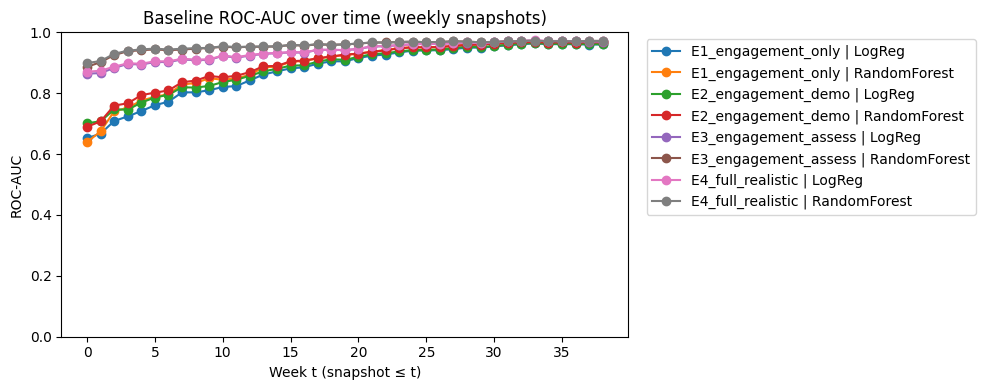

Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/tables/roc_auc_over_time.csv
Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/tables/recall_fail_over_time.csv
Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/tables/precision_fail_over_time.csv
Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/classification/tables/fbeta2_over_time.csv


In [14]:
# 8.1 ROC-AUC over time (plot + save)
plot_roc_over_time(
    results,
    title="Baseline ROC-AUC over time (weekly snapshots)",
    fname="baseline_roc_auc_over_time",
)

# 8.2 Pivot tables (export)
_ = export_pivot(results, value_col="roc_auc", out_name="roc_auc_over_time.csv")
_ = export_pivot(results, value_col="recall_fail", out_name="recall_fail_over_time.csv")
_ = export_pivot(results, value_col="precision_fail", out_name="precision_fail_over_time.csv")
_ = export_pivot(results, value_col="fbeta2", out_name="fbeta2_over_time.csv")
